Calculating Analytical Fock n = 0 ...
Calculating Analytical Fock n = 1 ...
Calculating Analytical Fock n = 2 ...
Calculating Analytical Fock n = 3 ...


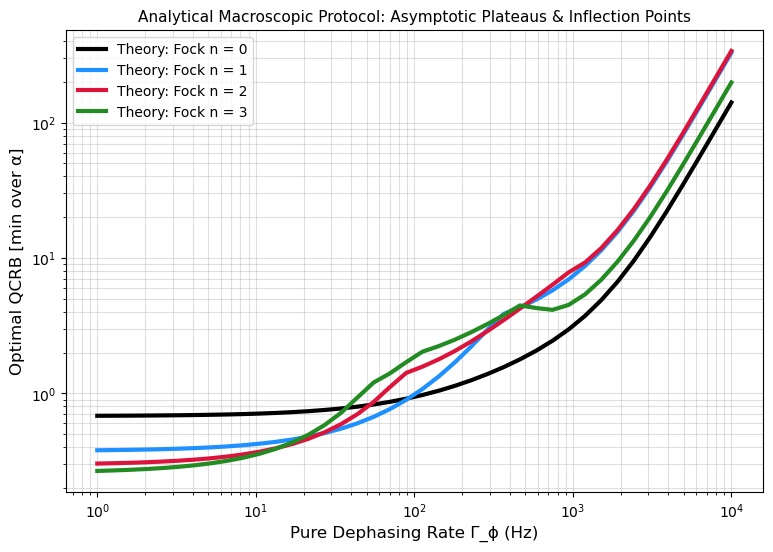

In [1]:
ENV["MPLBACKEND"] = "agg"
using QuantumOptics
using PyPlot

function get_fast_qcrb_vs_gamma_theory(n_focks=[0, 1, 2, 3], laser_intensity::Float64=1e3)
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    # Calculate physical time t_sig based on beta=1.0 and laser intensity
    transition_λ = 729e-9 # approximate for Ca40
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    eta = ((2 * π / transition_λ) / sqrt(2)) * z_zpf
    
    # Approximate Omega_eff from intensity (using a typical g factor)
    # For I=1000, g is approx 453.17 rad/s based on your earlier plots
    g_coupling = 453.17 
    Omega_eff = (g_coupling * 2.0) / eta
    
    target_time_s = (2 * 1.0) / (eta * Omega_eff)

    N_cut = 60
    b_fock = FockBasis(N_cut) 
    
    # Sweep Γ_φ from 1 to 10000 Hz
    gammas = 10 .^ range(0, stop=4, length=40) 
    alphas = collect(0.1:0.01:1.6) # Very fine sweep to perfectly catch the inflection snap

    results = Dict{Int, Vector{Float64}}()

    # The effective macroscopic distance the bath attacks. 
    # (For a moving target drifting to beta=1.0, the effective squared radius is roughly 1/3)
    effective_disp = 1.0 / sqrt(3.0) 

    for n in n_focks
        println("Calculating Analytical Fock n = $n ...")
        psi_init_qo = fockstate(b_fock, n)
        
        # Project the state at the macroscopic displacement
        rho_displaced = dm(QuantumOptics.displace(b_fock, effective_disp) * psi_init_qo)
        
        min_qcrbs = Float64[]
        
        for gamma_phi in gammas
            Gamma_t = gamma_phi * target_time_s
            continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0
            
            # Apply exact dephasing analytically to the density matrix
            rho_dephased = deepcopy(rho_displaced)
            for i in 1:(N_cut + 1)
                for j in 1:(N_cut + 1)
                    rho_dephased.data[i, j] *= exp(-0.5 * Gamma_t * ((i - 1) - (j - 1))^2)
                end
            end
            
            # Shift the state back to the origin frame to evaluate the alpha readout overlap
            rho_readout_frame = QuantumOptics.displace(b_fock, -effective_disp) * rho_dephased * QuantumOptics.displace(b_fock, effective_disp)

            current_gamma_min_qcrb = Inf
            
            # Instantly sweep α using the V_open characteristic equation
            for a in alphas
                V_open = real(expect(QuantumOptics.displace(b_fock, -2.0 * a), rho_readout_frame))
                
                # Full QCRB including envelope smearing (V_open) and continuous drag (Φ)
                qcrb_theory = 1.0 / (16.0 * a^2 * (continuous_signal_factor^2) * V_open^2)
                
                if qcrb_theory < current_gamma_min_qcrb
                    current_gamma_min_qcrb = qcrb_theory
                end
            end
            push!(min_qcrbs, current_gamma_min_qcrb)
        end
        results[n] = min_qcrbs
    end

    return gammas, results
end

function plot_fast_qcrb_vs_gamma(n_focks=[0, 1, 2, 3], laser_intensity=1e3)
    gammas, results = get_fast_qcrb_vs_gamma_theory(n_focks, laser_intensity)

    fig = figure(figsize=(9, 6))
    colors = ["black", "dodgerblue", "crimson", "forestgreen"]
    
    for (i, n) in enumerate(n_focks)
        plot(gammas, results[n], "-", linewidth=3.0, color=colors[i], label="Theory: Fock n = $n")
    end

    xscale("log")
    yscale("log")
    xlabel("Pure Dephasing Rate Γ_ϕ (Hz)", fontsize=12)
    ylabel("Optimal QCRB [min over α]", fontsize=12)
    title("Analytical Macroscopic Protocol: Asymptotic Plateaus & Inflection Points", fontsize=11)
    
    legend(fontsize=10, loc="upper left")
    grid(alpha=0.4, which="both")
    
    display(fig)
end

plot_fast_qcrb_vs_gamma([0, 1, 2, 3], 1e3)

 EXPANDED MACROSCOPIC β=1.0 ANALYSIS (Fock n = 0 to 6)

Computed Asymptotic Prefactors (Γ_ϕ * t_sig -> ∞):
  Fock n=0 : K_n = 0.2892 | log10(K_n) = -0.5389
  Fock n=1 : K_n = 0.6745 | log10(K_n) = -0.171
  Fock n=2 : K_n = 0.6954 | log10(K_n) = -0.1578
  Fock n=3 : K_n = 0.3968 | log10(K_n) = -0.4014
  Fock n=4 : K_n = 0.4362 | log10(K_n) = -0.3603
  Fock n=5 : K_n = 0.7324 | log10(K_n) = -0.1352
  Fock n=6 : K_n = 0.6728 | log10(K_n) = -0.1721


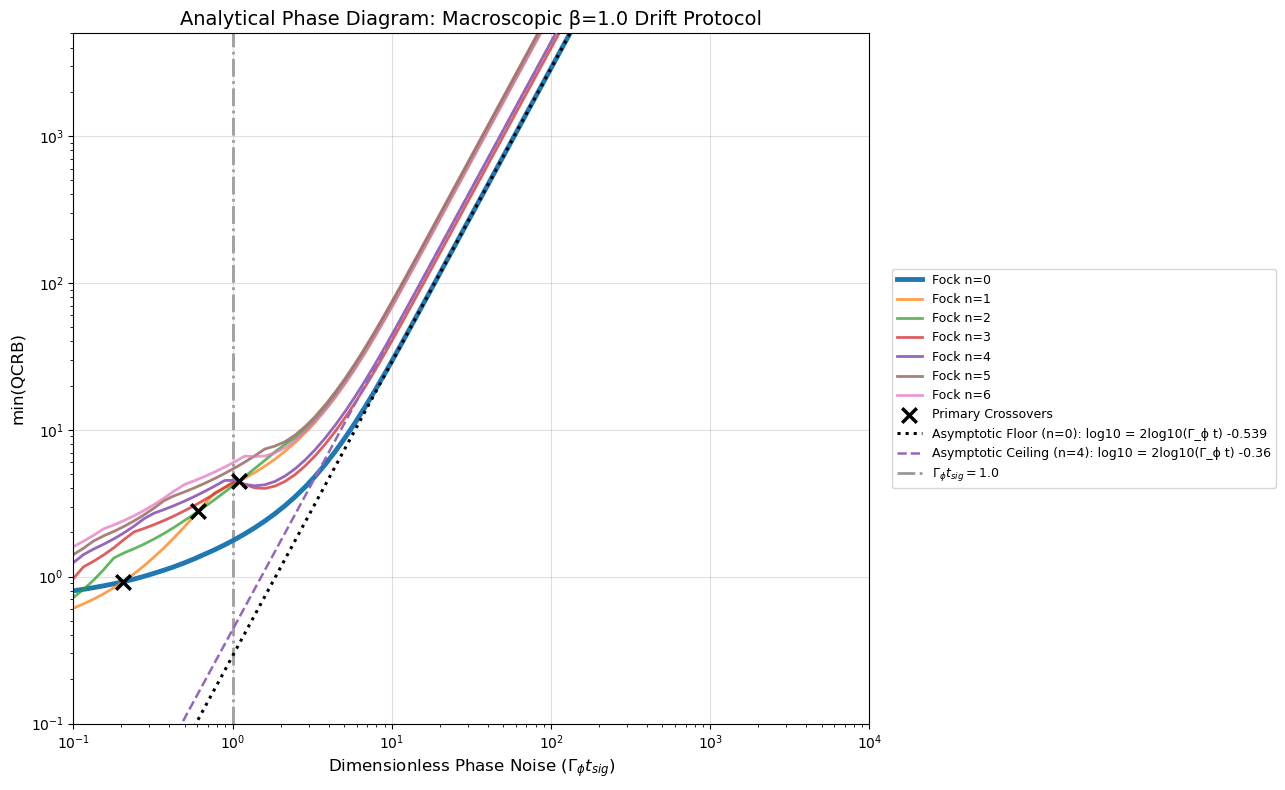

In [2]:
ENV["MPLBACKEND"] = "agg"
using PyPlot
using QuantumOptics
using IonSim

# -------------------------------------------------------------
# Exact Numerical Ancilla QCRB (Macroscopic β=1.0 Drift Protocol)
# -------------------------------------------------------------
function get_dephased_ancilla_qcrb(n_fock::Int, Gamma_t::Float64)
    N_cut = 80 
    b = FockBasis(N_cut)
    
    # Continuous phase drag factor from the beta drive
    continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0

    # Effective static displacement for a moving target drifting to β=1.0 (squared integral average)
    beta_eff = 1.0 / sqrt(3.0) 
    
    psi_initial = fockstate(b, n_fock)
    
    # 1. Displace wavepacket to the macroscopic effective radius BEFORE applying noise
    D_beta = displace(b, beta_eff)
    rho_displaced = dm(D_beta * psi_initial)
    
    # 2. Apply pure dephasing analytically in the Fock basis at this macroscopic distance
    rho_dephased = deepcopy(rho_displaced)
    for i in 1:(N_cut + 1)
        for j in 1:(N_cut + 1)
            n_i = i - 1
            n_j = j - 1
            rho_dephased.data[i, j] *= exp(-0.5 * Gamma_t * (n_i - n_j)^2)
        end
    end
    
    # 3. Shift the smeared state back to the origin frame for the instantaneous α readout
    D_beta_inv = displace(b, -beta_eff)
    rho_readout_frame = D_beta_inv * rho_dephased * D_beta
    
    alpha_sweep = range(0.05, stop=4.0, length=140)
    min_qcrb = Inf
    
    for alpha in alpha_sweep
        # Instantaneous SDF split overlap (Eq 53) evaluated over the degraded state
        V_op = displace(b, -2.0 * alpha)
        V_val = real(expect(V_op, rho_readout_frame))
        
        if abs(V_val) > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * (continuous_signal_factor^2) * V_val^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
            end
        end
    end
    return min_qcrb
end

# -------------------------------------------------------------
# Analytical Infinite-Noise Coefficient K_n (Γ_ϕ * t_sig -> ∞)
# -------------------------------------------------------------
function get_asymptotic_prefactor_K(n_fock::Int)
    N_cut = 80
    b = FockBasis(N_cut)
    psi_initial = fockstate(b, n_fock)
    
    # The infinite noise limit strips coherences from the macroscopically displaced state
    beta_eff = 1.0 / sqrt(3.0)
    psi_disp = displace(b, beta_eff) * psi_initial
    
    alpha_sweep = range(0.05, stop=4.0, length=350)
    min_K = Inf

    for alpha in alpha_sweep
        V_op = displace(b, -2.0 * alpha)
        
        V_inf = 0.0
        for j in 1:(N_cut + 1)
            # Probability distribution of the macroscopically displaced state
            prob_j = abs2(psi_disp.data[j]) 
            
            # Since β and α are real, D(-β)D(-2α)D(β) = D(-2α), avoiding complex phase offsets
            V_inf += prob_j * real(V_op.data[j, j])
        end
        
        if abs(V_inf) > 1e-10
            K_val = 1.0 / (64.0 * alpha^2 * V_inf^2)
            if K_val < min_K
                min_K = K_val
            end
        end
    end
    return min_K
end

# -------------------------------------------------------------
# Multi-Root Bracketed Logarithmic Bisection Finder
# -------------------------------------------------------------
function find_all_crossovers(n1::Int, n2::Int, grid::Vector{Float64}, qcrb1::Vector{Float64}, qcrb2::Vector{Float64}; tol=1e-5)
    f(g) = get_dephased_ancilla_qcrb(n1, g) - get_dephased_ancilla_qcrb(n2, g)
    roots = Tuple{Float64, Float64}[]

    for i in 1:(length(grid) - 1)
        val_min = qcrb1[i] - qcrb2[i]
        val_max = qcrb1[i+1] - qcrb2[i+1]

        if sign(val_min) != sign(val_max)
            g_min, g_max = grid[i], grid[i+1]
            g_mid = g_min
            for _ in 1:35
                g_mid = 10.0^((log10(g_min) + log10(g_max)) / 2.0)
                val_mid = f(g_mid)
                if abs(val_mid) < tol || abs(g_max - g_min) < tol
                    break
                end
                if sign(val_mid) == sign(val_min)
                    g_min = g_mid
                    val_min = val_mid
                else
                    g_max = g_mid
                    val_max = val_mid
                end
            end
            push!(roots, (g_mid, get_dephased_ancilla_qcrb(n1, g_mid)))
        end
    end
    return roots
end

# -------------------------------------------------------------
# Macroscopic β=1.0 Pure Dephasing Phase Diagram
# -------------------------------------------------------------
function plot_numerical_dephasing_crossover_expanded(laser_intensity::Float64=1e3)
    n_vals = [0, 1, 2, 3, 4, 5, 6]
    g_min_sweep = 1e-1  # Shifted minimum up slightly to focus on the active plateau regime
    g_max_sweep = 1e4   # Extended maximum to clearly visualize the flat asymptotic limit
    gamma_t_sweep = 10.0 .^ range(log10(g_min_sweep), log10(g_max_sweep), length=80)
    
    state_colors = Dict(0=>"C0", 1=>"C1", 2=>"C2", 3=>"C3", 4=>"C4", 5=>"C5", 6=>"C6")

    trap_freq = 19e5; hbar = 1.0545718e-34; amu = 1.66053906e-27; m_Ca40 = 39.96259 * amu
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    z_zpf = sqrt(hbar / (2 * m_Ca40 * 2 * π * trap_freq))
    eta = ((2 * π / transition_λ) / sqrt(2)) * z_zpf
    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=transition_λ)
    Omega_eff = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0)) * 2 * π
    t_sig_s = 2.0 / (eta * Omega_eff)

    fig = figure(figsize=(13, 8))
    println("==========================================================")
    println(" EXPANDED MACROSCOPIC β=1.0 ANALYSIS (Fock n = 0 to 6)")
    println("==========================================================")

    qcrb_dict = Dict{Int, Vector{Float64}}()
    for n in n_vals
        qcrb_dict[n] = [get_dephased_ancilla_qcrb(n, gt) for gt in gamma_t_sweep]
        lw = n == 0  ? 3.5 : 2.0
        alpha_val = n == 0 || n == 4 ? 1.0 : 0.75
        plot(gamma_t_sweep, qcrb_dict[n], color=state_colors[n], linewidth=lw, alpha=alpha_val, label="Fock n=$n", zorder=2)
    end

    crossovers_to_find = [(3, 2), (2, 1), (1, 0)]
    primary_x = Float64[]; primary_y = Float64[]
    for (nA, nB) in crossovers_to_find
        roots = find_all_crossovers(nA, nB, gamma_t_sweep, qcrb_dict[nA], qcrb_dict[nB])
        if !isempty(roots)
            push!(primary_x, roots[1][1]); push!(primary_y, roots[1][2])
        end
    end
    scatter(primary_x, primary_y, color="black", s=110, zorder=5, marker="x", linewidths=2.5, label="Primary Crossovers")

    K0 = get_asymptotic_prefactor_K(0)
    K4 = get_asymptotic_prefactor_K(4)
    plot(gamma_t_sweep, K0 .* (gamma_t_sweep .^ 2), "k:", linewidth=2.2, zorder=3,
         label="Asymptotic Floor (n=0): log10 = 2log10(Γ_ϕ t) $(round(log10(K0), digits=3))")
    plot(gamma_t_sweep, K4 .* (gamma_t_sweep .^ 2), color="C4", linestyle="--", linewidth=1.8, zorder=3,
         label="Asymptotic Ceiling (n=4): log10 = 2log10(Γ_ϕ t) $(round(log10(K4), digits=3))")

    println("\nComputed Asymptotic Prefactors (Γ_ϕ * t_sig -> ∞):")
    for n in n_vals
        Kn = get_asymptotic_prefactor_K(n)
        println("  Fock n=$n : K_n = $(round(Kn, digits=4)) | log10(K_n) = $(round(log10(Kn), digits=4))")
    end
    println("==========================================================")

    axvline(x=1.0, color="gray", linestyle="-.", linewidth=2.0, alpha=0.8, label=L"\Gamma_\phi t_{sig} = 1.0", zorder=1)

    xscale("log"); yscale("log")
    xlim(g_min_sweep, g_max_sweep)
    ylim(1e-1, 5e3) # Scaled bounds appropriately for macroscopic beta limits

    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Analytical Phase Diagram: Macroscopic β=1.0 Drift Protocol", fontsize=14)
    grid(alpha=0.4)
    legend(fontsize=9.0, loc="center left", bbox_to_anchor=(1.02, 0.5))
    tight_layout()

    display(fig)
end

plot_numerical_dephasing_crossover_expanded(1e3)

In [ ]:
ENV["MPLBACKEND"] = "agg"
using PyPlot
using QuantumOptics
using IonSim

# -------------------------------------------------------------
# Solver: Returns both min(QCRB) and the Optimal Alpha used
# -------------------------------------------------------------
function get_qcrb_and_opt_alpha(n_fock::Int, Gamma_t::Float64)
    N_cut = 70 
    b = FockBasis(N_cut)
    
    # High resolution alpha sweep to cleanly track the valleys
    alpha_sweep = range(0.05, stop=3.0, length=250)
    min_qcrb = Inf
    opt_alpha = 0.0
    
    psi_initial = fockstate(b, n_fock)
    continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0
    
    for alpha in alpha_sweep
        D_op = displace(b, alpha)
        rho = dm(D_op * psi_initial)
        
        # Apply Pure Dephasing across full FockBasis dimension (N_cut + 1)
        for i in 1:(N_cut + 1)
            for j in 1:(N_cut + 1)
                rho.data[i, j] *= exp(-0.5 * Gamma_t * (i - j)^2)
            end
        end
        
        V_val = real(expect(displace(b, -2.0 * alpha), rho))
        
        if abs(V_val) > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * (continuous_signal_factor^2) * V_val^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
                opt_alpha = alpha
            end
        end
    end
    
    return min_qcrb, opt_alpha
end

# -------------------------------------------------------------
# Phase Diagram Kink Finder (Returns both Gamma_t and Gamma_Hz)
# -------------------------------------------------------------
function extract_internal_inflections(n_fock::Int=3, laser_intensity::Float64=1e3)
    # 1. Calculate physical exposure time t_sig from trap parameters
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    eta = ((2 * π / transition_λ) / sqrt(2)) * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=transition_λ)
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0))
    Omega_eff = Omega_eff_Hz * 2 * π
    
    beta_signal = 1.0
    t_sig_s = (2 * beta_signal) / (eta * Omega_eff)
    t_sig_us = t_sig_s * 1e6
    g_display = round((eta * Omega_eff) / 2.0, digits=2)

    # 2. Sweep dimensionless phase noise
    gamma_t_sweep = 10.0 .^ range(-3.0, 1.0, length=200)
    
    qcrbs = Float64[]
    opt_alphas = Float64[]
    
    println("==================================================")
    println(" TRACKING OPTIMAL CONTROL TRANSITIONS (n=$n_fock)")
    println("==================================================")
    println(" Laser Intensity (I) : ", laser_intensity, " W/m^2")
    println(" Coupling Rate (g)   : ", g_display, " rad/s")
    println(" Exposure Time (t)   : ", round(t_sig_us, digits=2), " μs")
    println("==================================================")
    println("Tracking optimal control parameters for n=$n_fock... (May take 10-20 seconds)")
    
    for gt in gamma_t_sweep
        q, a = get_qcrb_and_opt_alpha(n_fock, gt)
        push!(qcrbs, q)
        push!(opt_alphas, a)
    end
    
    kink_gammas_t = Float64[]
    kink_gammas_hz = Float64[]
    kink_qcrbs = Float64[]
    kink_alpha_jumps = Tuple{Float64, Float64}[]
    
    # 3. Detect discontinuous "snaps" in the optimal alpha
    for i in 2:length(opt_alphas)
        if (opt_alphas[i-1] - opt_alphas[i]) > 0.15
            gt_val = gamma_t_sweep[i]
            ghz_val = gt_val / t_sig_s
            
            push!(kink_gammas_t, gt_val)
            push!(kink_gammas_hz, ghz_val)
            push!(kink_qcrbs, qcrbs[i])
            push!(kink_alpha_jumps, (opt_alphas[i-1], opt_alphas[i]))
        end
    end
    
    # 4. Plotting
    fig = figure(figsize=(10, 7))
    
    plot(gamma_t_sweep, qcrbs, color="C3", linewidth=3.5, label="Fock n=$n_fock (With Φ Damping)")
    
    println("\n==================================================")
    println(" INTERNAL INFLECTION POINTS DETECTED (n=$n_fock)")
    println("==================================================")
    
    for (idx, (gt_val, ghz_val, q_val, a_jump)) in enumerate(zip(kink_gammas_t, kink_gammas_hz, kink_qcrbs, kink_alpha_jumps))
        scatter([gt_val], [q_val], color="black", s=120, zorder=5, marker="X")
        
        println("Inflection Point $idx:")
        println("  Dimensionless Noise (Γ_ϕ t_sig) : ", round(gt_val, digits=4))
        println("  Physical Dephasing (Γ_ϕ)        : ", round(ghz_val, digits=2), " Hz")
        println("  QCRB Discontinuity              : ", round(q_val, digits=4))
        println("  Optimal α Snapped Inward        : From $(round(a_jump[1], digits=2)) -> $(round(a_jump[2], digits=2))")
        println("--------------------------------------------------")
    end
    
    scatter([], [], color="black", s=100, marker="X", label="Optimal α Phase Transitions")
    
    xscale("log"); yscale("log")
    xlim(1e-3, 1e1); ylim(1e-1, 1e2)
    
    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Tracking Inflection Points in the n=$n_fock Phase Diagram (I = $laser_intensity)", fontsize=13)
    grid(alpha=0.4)
    legend(fontsize=11, loc="upper left")
    
    display(fig)
    
    return kink_gammas_t, kink_gammas_hz, kink_qcrbs, kink_alpha_jumps
end

# Extract the kinks and capture the returned (Gamma_t, Gamma_Hz) arrays
gamma_t_pts, gamma_hz_pts, qcrb_pts, alpha_jumps = extract_internal_inflections(3, 1e3)

 TRACKING OPTIMAL CONTROL TRANSITIONS (n=3)

 INTERNAL INFLECTION POINTS DETECTED (n=3)
Inflection Point 1:
  Dimensionless Noise (Γ_ϕ t_sig) : 0.1196
  Physical Dephasing (Γ_ϕ)        : 54.22 Hz
  QCRB Discontinuity              : 1.186
  Optimal α Snapped Inward        : From 1.57 -> 1.0
--------------------------------------------------
Inflection Point 2:
  Dimensionless Noise (Γ_ϕ t_sig) : 0.2396
  Physical Dephasing (Γ_ϕ)        : 108.56 Hz
  QCRB Discontinuity              : 2.0035
  Optimal α Snapped Inward        : From 0.99 -> 0.55
--------------------------------------------------


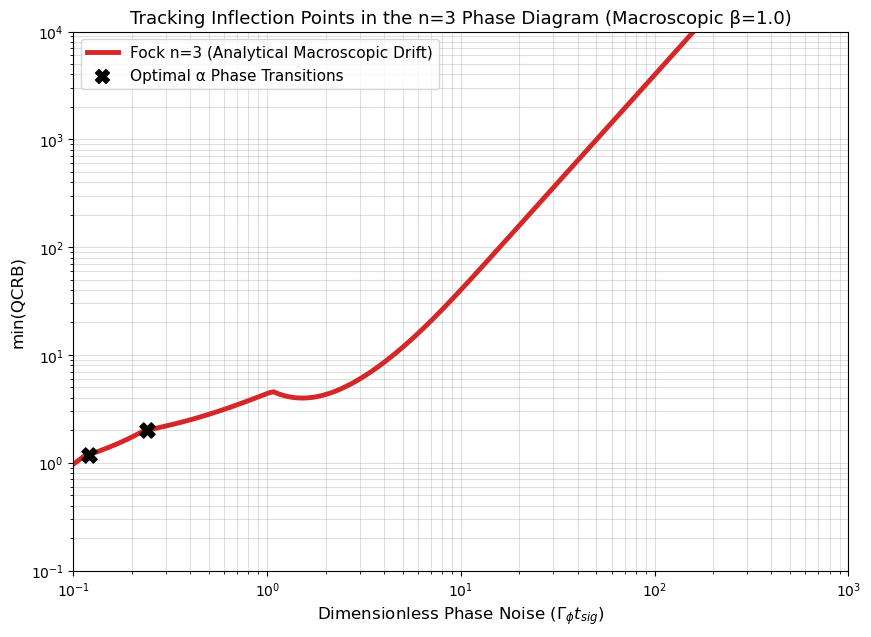

([0.11964359312238489, 0.2395504466349916], [54.218958778776816, 108.55721942632081], [1.186041835810717, 2.0034522573162095], [(1.5664658634538153, 0.9977911646586345), (0.9859437751004017, 0.5475903614457831)])

In [3]:
ENV["MPLBACKEND"] = "agg"
using PyPlot
using QuantumOptics
using IonSim

# -------------------------------------------------------------
# Exact Analytical Macroscopic β=1.0 QCRB Solver
# -------------------------------------------------------------
function get_qcrb_and_opt_alpha(n_fock::Int, Gamma_t::Float64)
    N_cut = 70 
    b = FockBasis(N_cut)
    
    alpha_sweep = range(0.05, stop=3.0, length=250)
    min_qcrb = Inf
    opt_alpha = 0.0
    
    # Continuous phase drag on the signal
    continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0
    
    # Macroscopic moving target effective radius
    beta_eff = 1.0 / sqrt(3.0) 
    
    psi_initial = fockstate(b, n_fock)
    
    # 1. Drift wavepacket to macroscopic target
    D_beta = displace(b, beta_eff)
    rho_displaced = dm(D_beta * psi_initial)
    
    # 2. Apply pure dephasing in the Fock basis
    rho_dephased = deepcopy(rho_displaced)
    for i in 1:(N_cut + 1)
        for j in 1:(N_cut + 1)
            rho_dephased.data[i, j] *= exp(-0.5 * Gamma_t * (i - j)^2)
        end
    end
    
    # 3. Shift back to the origin frame for instantaneous SDF split readout
    D_beta_inv = displace(b, -beta_eff)
    rho_readout_frame = D_beta_inv * rho_dephased * D_beta
    
    for alpha in alpha_sweep
        V_val = real(expect(displace(b, -2.0 * alpha), rho_readout_frame))
        
        if abs(V_val) > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * (continuous_signal_factor^2) * V_val^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
                opt_alpha = alpha
            end
        end
    end
    
    return min_qcrb, opt_alpha
end

# -------------------------------------------------------------
# Phase Diagram Kink Finder
# -------------------------------------------------------------
function extract_internal_inflections(n_fock::Int=3, laser_intensity::Float64=1e3)
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    eta = ((2 * π / transition_λ) / sqrt(2)) * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=transition_λ)
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0))
    Omega_eff = Omega_eff_Hz * 2 * π
    
    beta_signal = 1.0
    t_sig_s = (2 * beta_signal) / (eta * Omega_eff)
    t_sig_us = t_sig_s * 1e6
    g_display = round((eta * Omega_eff) / 2.0, digits=2)

    gamma_t_sweep = 10.0 .^ range(-1.5, 3.5, length=200)
    
    qcrbs = Float64[]
    opt_alphas = Float64[]
    
    println("==================================================")
    println(" TRACKING OPTIMAL CONTROL TRANSITIONS (n=$n_fock)")
    println("==================================================")
    
    for gt in gamma_t_sweep
        q, a = get_qcrb_and_opt_alpha(n_fock, gt)
        push!(qcrbs, q)
        push!(opt_alphas, a)
    end
    
    kink_gammas_t = Float64[]
    kink_gammas_hz = Float64[]
    kink_qcrbs = Float64[]
    kink_alpha_jumps = Tuple{Float64, Float64}[]
    
    for i in 2:length(opt_alphas)
        if (opt_alphas[i-1] - opt_alphas[i]) > 0.15
            gt_val = gamma_t_sweep[i]
            ghz_val = gt_val / t_sig_s
            
            push!(kink_gammas_t, gt_val)
            push!(kink_gammas_hz, ghz_val)
            push!(kink_qcrbs, qcrbs[i])
            push!(kink_alpha_jumps, (opt_alphas[i-1], opt_alphas[i]))
        end
    end
    
    fig = figure(figsize=(10, 7))
    plot(gamma_t_sweep, qcrbs, color="C3", linewidth=3.5, label="Fock n=$n_fock (Analytical Macroscopic Drift)")
    
    println("\n==================================================")
    println(" INTERNAL INFLECTION POINTS DETECTED (n=$n_fock)")
    println("==================================================")
    
    for (idx, (gt_val, ghz_val, q_val, a_jump)) in enumerate(zip(kink_gammas_t, kink_gammas_hz, kink_qcrbs, kink_alpha_jumps))
        scatter([gt_val], [q_val], color="black", s=120, zorder=5, marker="X")
        
        println("Inflection Point $idx:")
        println("  Dimensionless Noise (Γ_ϕ t_sig) : ", round(gt_val, digits=4))
        println("  Physical Dephasing (Γ_ϕ)        : ", round(ghz_val, digits=2), " Hz")
        println("  QCRB Discontinuity              : ", round(q_val, digits=4))
        println("  Optimal α Snapped Inward        : From $(round(a_jump[1], digits=2)) -> $(round(a_jump[2], digits=2))")
        println("--------------------------------------------------")
    end
    
    scatter([], [], color="black", s=100, marker="X", label="Optimal α Phase Transitions")
    
    xscale("log"); yscale("log")
    xlim(1e-1, 1e3); ylim(1e-1, 1e4)
    
    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Tracking Inflection Points in the n=$n_fock Phase Diagram (Macroscopic β=1.0)", fontsize=13)
    grid(alpha=0.4, which="both")
    legend(fontsize=11, loc="upper left")
    
    display(fig)
    
    return kink_gammas_t, kink_gammas_hz, kink_qcrbs, kink_alpha_jumps
end

gamma_t_pts, gamma_hz_pts, qcrb_pts, alpha_jumps = extract_internal_inflections(3, 1e3)

 EXPANDED MACROSCOPIC β=1.0 ANALYSIS (Fock n = 0 to 6)

Computed Asymptotic Prefactors (Γ_ϕ * t_sig -> ∞):
  Fock n=0 : K_n = 0.2892 | log10(K_n) = -0.5389
  Fock n=1 : K_n = 0.6745 | log10(K_n) = -0.171
  Fock n=2 : K_n = 0.6954 | log10(K_n) = -0.1578
  Fock n=3 : K_n = 0.3968 | log10(K_n) = -0.4014
  Fock n=4 : K_n = 0.4362 | log10(K_n) = -0.3603
  Fock n=5 : K_n = 0.7324 | log10(K_n) = -0.1352
  Fock n=6 : K_n = 0.6728 | log10(K_n) = -0.1721


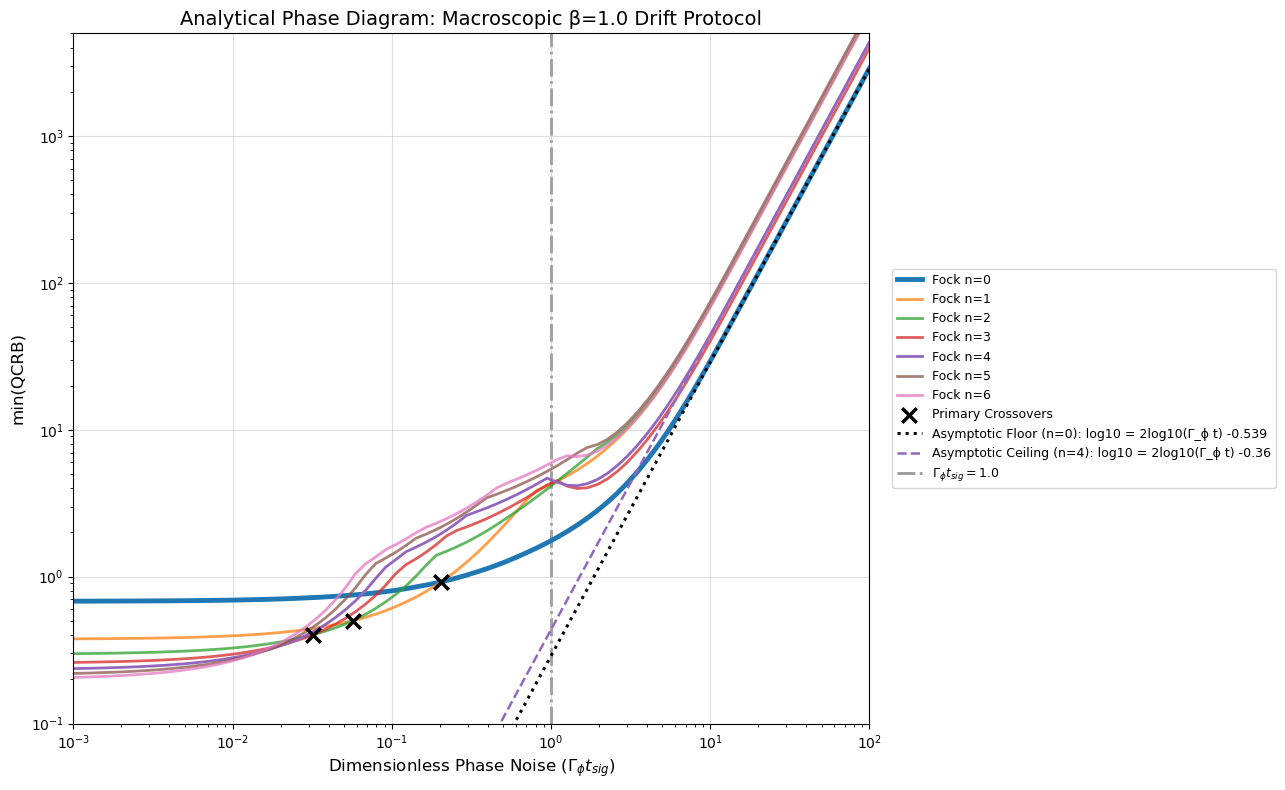

In [4]:

# -------------------------------------------------------------
# Exact Numerical Ancilla QCRB (Macroscopic β=1.0 Drift Protocol)
# -------------------------------------------------------------
function get_dephased_ancilla_qcrb(n_fock::Int, Gamma_t::Float64)
    N_cut = 80 
    b = FockBasis(N_cut)
    
    # Continuous phase drag factor from the beta drive
    continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0

    # Effective static displacement for a moving target drifting to β=1.0 (squared integral average)
    beta_eff = 1.0 / sqrt(3.0) 
    
    psi_initial = fockstate(b, n_fock)
    
    # 1. Displace wavepacket to the macroscopic effective radius BEFORE applying noise
    D_beta = displace(b, beta_eff)
    rho_displaced = dm(D_beta * psi_initial)
    
    # 2. Apply pure dephasing analytically in the Fock basis at this macroscopic distance
    rho_dephased = deepcopy(rho_displaced)
    for i in 1:(N_cut + 1)
        for j in 1:(N_cut + 1)
            n_i = i - 1
            n_j = j - 1
            rho_dephased.data[i, j] *= exp(-0.5 * Gamma_t * (n_i - n_j)^2)
        end
    end
    
    # 3. Shift the smeared state back to the origin frame for the instantaneous α readout
    D_beta_inv = displace(b, -beta_eff)
    rho_readout_frame = D_beta_inv * rho_dephased * D_beta
    
    alpha_sweep = range(0.05, stop=4.0, length=140)
    min_qcrb = Inf
    
    for alpha in alpha_sweep
        # Instantaneous SDF split overlap (Eq 53) evaluated over the degraded state
        V_op = displace(b, -2.0 * alpha)
        V_val = real(expect(V_op, rho_readout_frame))
        
        if abs(V_val) > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * (continuous_signal_factor^2) * V_val^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
            end
        end
    end
    return min_qcrb
end

# -------------------------------------------------------------
# Analytical Infinite-Noise Coefficient K_n (Γ_ϕ * t_sig -> ∞)
# -------------------------------------------------------------
function get_asymptotic_prefactor_K(n_fock::Int)
    N_cut = 80
    b = FockBasis(N_cut)
    psi_initial = fockstate(b, n_fock)
    
    # The infinite noise limit strips coherences from the macroscopically displaced state
    beta_eff = 1.0 / sqrt(3.0)
    psi_disp = displace(b, beta_eff) * psi_initial
    
    alpha_sweep = range(0.05, stop=4.0, length=350)
    min_K = Inf

    for alpha in alpha_sweep
        V_op = displace(b, -2.0 * alpha)
        
        V_inf = 0.0
        for j in 1:(N_cut + 1)
            # Probability distribution of the macroscopically displaced state
            prob_j = abs2(psi_disp.data[j]) 
            
            # Since β and α are real, D(-β)D(-2α)D(β) = D(-2α), avoiding complex phase offsets
            V_inf += prob_j * real(V_op.data[j, j])
        end
        
        if abs(V_inf) > 1e-10
            K_val = 1.0 / (64.0 * alpha^2 * V_inf^2)
            if K_val < min_K
                min_K = K_val
            end
        end
    end
    return min_K
end

# -------------------------------------------------------------
# Multi-Root Bracketed Logarithmic Bisection Finder
# -------------------------------------------------------------
function find_all_crossovers(n1::Int, n2::Int, grid::Vector{Float64}, qcrb1::Vector{Float64}, qcrb2::Vector{Float64}; tol=1e-5)
    f(g) = get_dephased_ancilla_qcrb(n1, g) - get_dephased_ancilla_qcrb(n2, g)
    roots = Tuple{Float64, Float64}[]

    for i in 1:(length(grid) - 1)
        val_min = qcrb1[i] - qcrb2[i]
        val_max = qcrb1[i+1] - qcrb2[i+1]

        if sign(val_min) != sign(val_max)
            g_min, g_max = grid[i], grid[i+1]
            g_mid = g_min
            for _ in 1:35
                g_mid = 10.0^((log10(g_min) + log10(g_max)) / 2.0)
                val_mid = f(g_mid)
                if abs(val_mid) < tol || abs(g_max - g_min) < tol
                    break
                end
                if sign(val_mid) == sign(val_min)
                    g_min = g_mid
                    val_min = val_mid
                else
                    g_max = g_mid
                    val_max = val_mid
                end
            end
            push!(roots, (g_mid, get_dephased_ancilla_qcrb(n1, g_mid)))
        end
    end
    return roots
end

# -------------------------------------------------------------
# Macroscopic β=1.0 Pure Dephasing Phase Diagram
# -------------------------------------------------------------
function plot_numerical_dephasing_crossover_expanded(laser_intensity::Float64=1e3)
    n_vals = [0, 1, 2, 3, 4, 5, 6]
    g_min_sweep = 1e-3  # Shifted minimum up slightly to focus on the active plateau regime
    g_max_sweep = 1e2   # Extended maximum to clearly visualize the flat asymptotic limit
    gamma_t_sweep = 10.0 .^ range(log10(g_min_sweep), log10(g_max_sweep), length=80)
    
    state_colors = Dict(0=>"C0", 1=>"C1", 2=>"C2", 3=>"C3", 4=>"C4", 5=>"C5", 6=>"C6")

    trap_freq = 19e5; hbar = 1.0545718e-34; amu = 1.66053906e-27; m_Ca40 = 39.96259 * amu
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    z_zpf = sqrt(hbar / (2 * m_Ca40 * 2 * π * trap_freq))
    eta = ((2 * π / transition_λ) / sqrt(2)) * z_zpf
    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=transition_λ)
    Omega_eff = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0)) * 2 * π
    t_sig_s = 2.0 / (eta * Omega_eff)

    fig = figure(figsize=(13, 8))
    println("==========================================================")
    println(" EXPANDED MACROSCOPIC β=1.0 ANALYSIS (Fock n = 0 to 6)")
    println("==========================================================")

    qcrb_dict = Dict{Int, Vector{Float64}}()
    for n in n_vals
        qcrb_dict[n] = [get_dephased_ancilla_qcrb(n, gt) for gt in gamma_t_sweep]
        lw = n == 0  ? 3.5 : 2.0
        alpha_val = n == 0 || n == 4 ? 1.0 : 0.75
        plot(gamma_t_sweep, qcrb_dict[n], color=state_colors[n], linewidth=lw, alpha=alpha_val, label="Fock n=$n", zorder=2)
    end

    crossovers_to_find = [(3, 2), (2, 1), (1, 0)]
    primary_x = Float64[]; primary_y = Float64[]
    for (nA, nB) in crossovers_to_find
        roots = find_all_crossovers(nA, nB, gamma_t_sweep, qcrb_dict[nA], qcrb_dict[nB])
        if !isempty(roots)
            push!(primary_x, roots[1][1]); push!(primary_y, roots[1][2])
        end
    end
    scatter(primary_x, primary_y, color="black", s=110, zorder=5, marker="x", linewidths=2.5, label="Primary Crossovers")

    K0 = get_asymptotic_prefactor_K(0)
    K4 = get_asymptotic_prefactor_K(4)
    plot(gamma_t_sweep, K0 .* (gamma_t_sweep .^ 2), "k:", linewidth=2.2, zorder=3,
         label="Asymptotic Floor (n=0): log10 = 2log10(Γ_ϕ t) $(round(log10(K0), digits=3))")
    plot(gamma_t_sweep, K4 .* (gamma_t_sweep .^ 2), color="C4", linestyle="--", linewidth=1.8, zorder=3,
         label="Asymptotic Ceiling (n=4): log10 = 2log10(Γ_ϕ t) $(round(log10(K4), digits=3))")

    println("\nComputed Asymptotic Prefactors (Γ_ϕ * t_sig -> ∞):")
    for n in n_vals
        Kn = get_asymptotic_prefactor_K(n)
        println("  Fock n=$n : K_n = $(round(Kn, digits=4)) | log10(K_n) = $(round(log10(Kn), digits=4))")
    end
    println("==========================================================")

    axvline(x=1.0, color="gray", linestyle="-.", linewidth=2.0, alpha=0.8, label=L"\Gamma_\phi t_{sig} = 1.0", zorder=1)

    xscale("log"); yscale("log")
    xlim(g_min_sweep, g_max_sweep)
    ylim(1e-1, 5e3) # Scaled bounds appropriately for macroscopic beta limits

    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Analytical Phase Diagram: Macroscopic β=1.0 Drift Protocol", fontsize=14)
    grid(alpha=0.4)
    legend(fontsize=9.0, loc="center left", bbox_to_anchor=(1.02, 0.5))
    tight_layout()

    display(fig)
end

plot_numerical_dephasing_crossover_expanded(1e3)

 TRACKING OPTIMAL CONTROL TRANSITIONS (n=1)

 INTERNAL INFLECTION POINTS DETECTED (n=1)
Inflection Point 1:
  Dimensionless Noise (Γ_ϕ t_sig) : 0.8073
  Physical Dephasing (Γ_ϕ)        : 365.84 Hz
  QCRB Discontinuity              : 3.8604
  Optimal α Snapped Inward        : From 0.78 -> 0.24
--------------------------------------------------


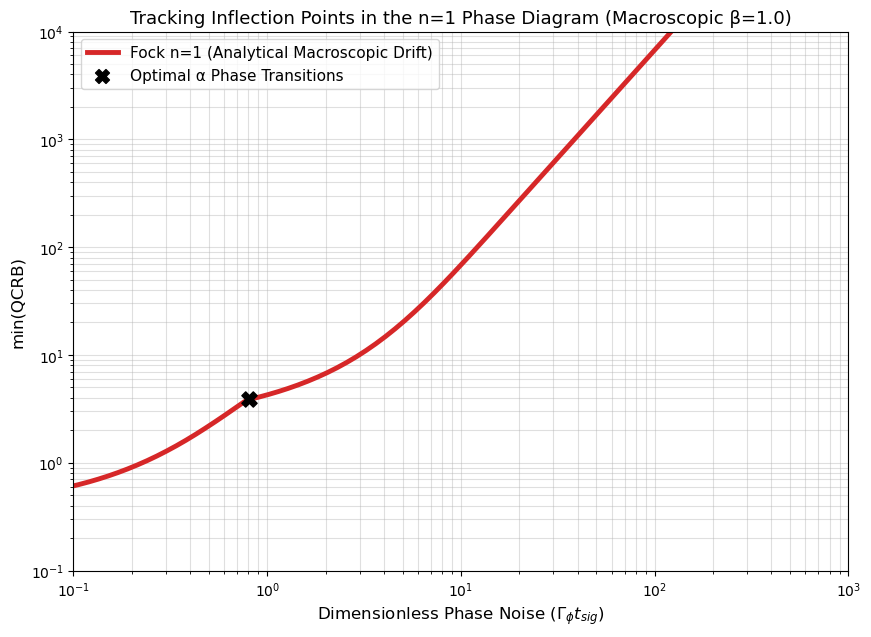

([0.8073004152657438], [365.8448128735894], [3.8603979053323414], [(0.7845381526104418, 0.2395582329317269)])

In [5]:
 extract_internal_inflections(1, 1e3)


Running master_dynamic (Drifting to macroscopic β=1.0 in the bath)...
Sweeping α (Applying instantaneous SDF Split)...


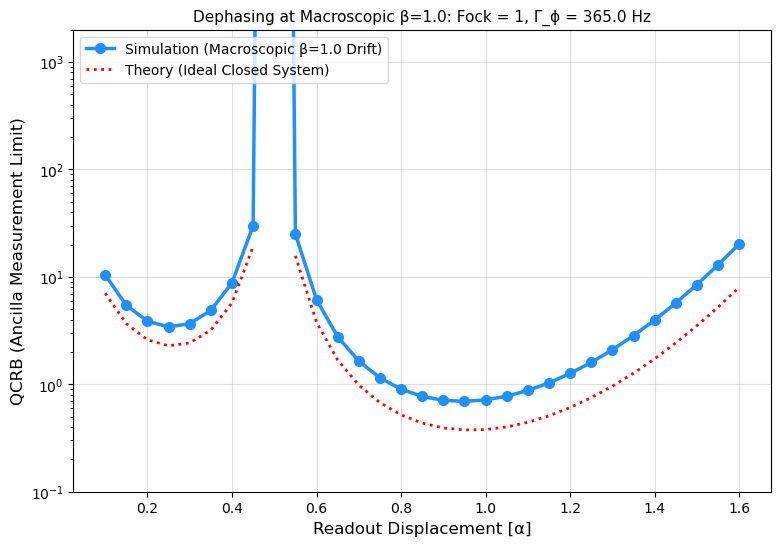

In [6]:
ENV["MPLBACKEND"] = "agg"
using IonSim
using QuantumOptics
using PyPlot
using LinearAlgebra

function laguerre(n::Int, x::Float64)
    if n == 0 return 1.0 end
    if n == 1 return 1.0 - x end
    L_prev2 = 1.0
    L_prev1 = 1.0 - x
    L_curr = 0.0
    for k in 1:(n-1)
        L_curr = ((2k + 1 - x) * L_prev1 - k * L_prev2) / (k + 1)
        L_prev2 = L_prev1
        L_prev1 = L_curr
    end
    return L_curr
end

function calculate_qcrb(state, state_perturbed, d_alpha::Float64; tol=1e-10)
    rho1 = isa(state, Ket) ? dm(state) : state
    rho2 = isa(state_perturbed, Ket) ? dm(state_perturbed) : state_perturbed
    
    rho_dense_data = dense(rho1).data
    rho_pert_dense_data = dense(rho2).data

    drho_data = (rho_pert_dense_data - rho_dense_data) / d_alpha
    λ, V = LinearAlgebra.eigen(Hermitian(rho_dense_data))
    
    qfi = 0.0
    n = length(λ)
    for i in 1:n
        for j in 1:n
            if real(λ[i] + λ[j]) > tol
                @views v_i = V[:, i]
                @views v_j = V[:, j]
                drho_ij = dot(v_i, drho_data * v_j)
                qfi += 2 * (abs(drho_ij)^2) / real(λ[i] + λ[j])
            end
        end
    end
    
    qcrb = qfi > 0 ? 1.0 / qfi : Inf
    return qfi, qcrb
end

function SDF_apply_with_alpha_dephasing(laser_intensity = 1e4, angle = 0.0, target_disp = 0.716, is_SDF = false, initial_state = nothing, fock_state_n = 0, gamma_phi_set = 1e-2)
    trap_freq = 19e5 
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    
    mode_z = zmodes(chain)[1] 
    mode_z.N = 50
    mode_z.shape = [51]
    
    k_vec = (x̂ + ẑ) / √2
    ϵ_vec = ŷ
    B_field = 1e-13
    
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    mode = zmodes(trap_pre)[1]
    
    ψ_ion = normalize(ion["g"])
    ψ_mode = fockstate(mode, fock_state_n)
    ψ_initial = initial_state !== nothing ? initial_state : (ψ_ion ⊗ ψ_mode)

    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_total = 2 * π / transition_λ
    k_z = k_total / sqrt(2)
    eta = k_z * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=k_vec, ϵ=ϵ_vec, λ=transition_λ)
    Bhat_tuple = (; x=0.0, y=0.0, z=1.0)
    
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), Bhat_tuple)
    Omega_eff = Omega_eff_Hz * 2 * π

    if is_SDF
        alpha_complex = target_disp * exp(1im * angle)
        g = ion["g"]
        e = ion["e"]
        
        x_plus = normalize(g + e)
        x_minus = normalize(g - e)
        
        P_plus = x_plus ⊗ dagger(x_plus)
        P_minus = x_minus ⊗ dagger(x_minus)
        
        D_plus = IonSim.displace(mode, alpha_complex)
        D_minus = IonSim.displace(mode, -alpha_complex)
        
        U_SDF = (P_plus ⊗ D_plus) + (P_minus ⊗ D_minus)
        
        if isa(ψ_initial, Operator)
            return U_SDF * ψ_initial * dagger(U_SDF)
        else
            return U_SDF * ψ_initial
        end
    else
        I_spin = identityoperator(ion["g"].basis)  
        gamma_phi_us = gamma_phi_set * 1e-6 

        temp_fock_basis = FockBasis(mode.N) 
        a_op = DenseOperator(mode, mode, QuantumOptics.destroy(temp_fock_basis).data)
        at_op = DenseOperator(mode, mode, QuantumOptics.create(temp_fock_basis).data)
        n_op = DenseOperator(mode, mode, QuantumOptics.number(temp_fock_basis).data)

        # Time is locked to a baseline to ensure equal noise exposure
        baseline_beta = 1.0 
        target_time_s = (2 * baseline_beta) / (eta * Omega_eff)
        target_time_us = target_time_s * 1e6

        # Drive amplitude scales with the actual requested target_disp (e.g. beta=1.0)
        drive_rate = target_disp / target_time_us
        H_m = (1im * drive_rate) * (exp(1im * angle) * at_op - exp(-1im * angle) * a_op)
        H_sys = I_spin ⊗ H_m

        n_sys = I_spin ⊗ n_op
        J_dephase = sqrt(gamma_phi_us) * n_sys
        J_ops = [J_dephase]
        J_ops_dag = dagger.(J_ops)

        function f_dyn(time_t, rho_state)
            return (H_sys, J_ops, J_ops_dag)
        end

        rho_initial = isa(ψ_initial, Ket) ? dm(ψ_initial) : ψ_initial
        tspan_sdf = [0.0, target_time_us]

        _, sol_beta = timeevolution.master_dynamic(tspan_sdf, rho_initial, f_dyn, reltol=1e-9, abstol=1e-11)

        return sol_beta[end]
    end
end

function get_qcrb_coordinates_macroscopic_beta(n_fock::Int=3, laser_intensity::Float64=1e3, gamma_phi::Float64=250.0)
    # The operating point is now MACROSCOPIC (beta = 1.0)
    beta_signal = 1.0
    d_beta = 1e-4 
    
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    sim_mode = zmodes(trap_pre)[1]
    sim_mode.N = 50
    sim_mode.shape = [51]

    N_cut = 50
    b_fock = FockBasis(N_cut) 
    psi_init_qo = fockstate(b_fock, n_fock)
    spin_g = normalize(ion["g"])

    initial_sys_origin = spin_g ⊗ Ket(sim_mode, psi_init_qo.data)

    println("\nRunning master_dynamic (Drifting to macroscopic β=1.0 in the bath)...")
    
    # Wavepacket drives to β=1.0 and β=1.0001 in the dephasing bath
    noisy_beta_state = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal, false, initial_sys_origin, n_fock, gamma_phi)
    noisy_beta_state_pert = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal + d_beta, false, initial_sys_origin, n_fock, gamma_phi)

    alphas = collect(0.1:0.05:1.6)
    sim_qcrbs = Float64[]
    theory_closed_qcrbs = Float64[]

    println("Sweeping α (Applying instantaneous SDF Split)...")
    for a in alphas
        state_a_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state, n_fock, gamma_phi)
        state_a_pert_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state_pert, n_fock, gamma_phi)

        rho_spin_a = ptrace(state_a_full, 2)
        rho_spin_a_pert = ptrace(state_a_pert_full, 2)
        
        _, qcrb_sim = calculate_qcrb(rho_spin_a, rho_spin_a_pert, d_beta)
        push!(sim_qcrbs, qcrb_sim)

        L_val = laguerre(n_fock, 4 * a^2)
        qcrb_closed = exp(4 * a^2) / (16 * a^2 * L_val^2)
        push!(theory_closed_qcrbs, qcrb_closed)
    end

    return alphas, sim_qcrbs, theory_closed_qcrbs
end

function plot_qcrb_macroscopic_beta(n_fock::Int=3, laser_intensity::Float64=1e3, gamma_phi::Float64=250.0)
    x_alpha, y_sim, y_closed = get_qcrb_coordinates_macroscopic_beta(n_fock, laser_intensity, gamma_phi)

    fig = figure(figsize=(9, 6))
    
    plot(x_alpha, y_sim, "o-", markersize=7, color="dodgerblue", linewidth=2.5, label="Simulation (Macroscopic β=1.0 Drift)")
    plot(x_alpha, y_closed, "r:", linewidth=2.0, label="Theory (Ideal Closed System)")

    yscale("log")
    ylim(1e-1, 2e3)
    xlabel("Readout Displacement [α]", fontsize=12)
    ylabel("QCRB (Ancilla Measurement Limit)", fontsize=12)
    title("Dephasing at Macroscopic β=1.0: Fock = $(n_fock), Γ_ϕ = $(gamma_phi) Hz", fontsize=11)
    
    legend(fontsize=10, loc="upper left")
    grid(alpha=0.4)
    
    display(fig)
end

plot_qcrb_macroscopic_beta(1, 1e3, 365.0)


Running master_dynamic (Drifting to macroscopic β=1.0 in the bath)...
Sweeping α (Applying instantaneous SDF Split)...


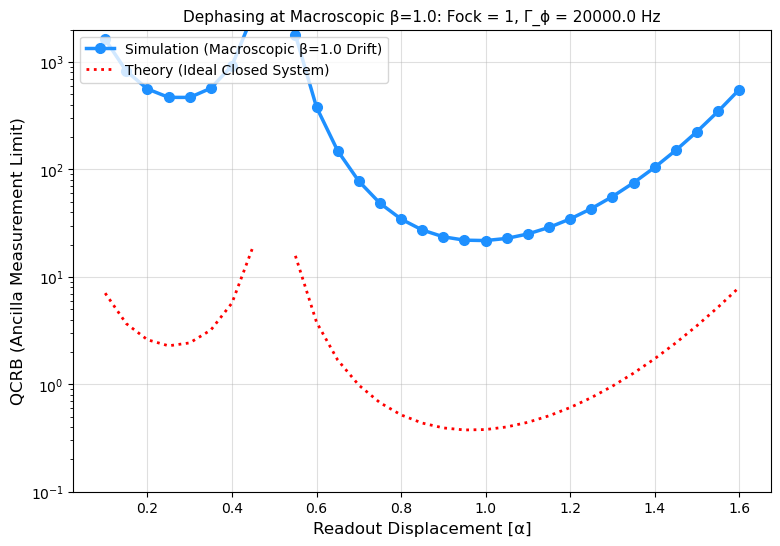

In [10]:
plot_qcrb_macroscopic_beta(1, 1e3, 20000.0)

In [20]:
beta_signal = 1.0
    d_beta = 1e-4 
    
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    sim_mode = zmodes(trap_pre)[1]
    sim_mode.N = 50
    sim_mode.shape = [51]

    N_cut = 50
    b_fock = FockBasis(N_cut) 
    psi_init_qo = fockstate(b_fock, 3)
    spin_g = normalize(ion["g"])

    initial_sys_origin = spin_g ⊗ Ket(sim_mode, psi_init_qo.data)

noisy_beta_state = SDF_apply_with_alpha_dephasing(1e3, 0.0, beta_signal, false, initial_sys_origin, 3, 0.0)

Operator(dim=102x102)
  basis: [⁴⁰Ca ⊗ VibrationalMode(ν=1.9e6, axis=ẑ, N=50)]
 0.0613132+0.0im  0.0+0.0im  …  0.0+0.0im  -0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im     0.0+0.0im   0.0+0.0im  0.0+0.0im
 -0.122626+0.0im  0.0+0.0im     0.0+0.0im   0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im     0.0+0.0im   0.0+0.0im  0.0+0.0im
  0.043355+0.0im  0.0+0.0im     0.0+0.0im  -0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im  …  0.0+0.0im   0.0+0.0im  0.0+0.0im
  0.100124+0.0im  0.0+0.0im     0.0+0.0im  -0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im     0.0+0.0im   0.0+0.0im  0.0+0.0im
 0.0125155+0.0im  0.0+0.0im     0.0+0.0im  -0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im     0.0+0.0im   0.0+0.0im  0.0+0.0im
          ⋮                  ⋱                 ⋮       
       0.0+0.0im  0.0+0.0im     0.0+0.0im   0.0+0.0im  0.0+0.0im
      -0.0+0.0im  0.0+0.0im     0.0+0.0im   0.0+0.0im  0.0+0.0im
       0.0+0.0im  0.0+0.0im  …  0.0+0.0im   0.0+0.0im  0.0+0.0im
      -0.0+0.0im  0

In [16]:
function plot_wigner(final_state)
    rho_motional = ptrace(final_state, 1)

b_fock = FockBasis(50)
rho_fock = DenseOperator(b_fock, rho_motional.data)

x_vec = -4.0:0.1:4.0
p_vec = -4.0:0.1:4.0

W = wigner(rho_fock, x_vec, p_vec)

fig = figure(figsize=(8, 6))
PyPlot.pcolormesh(x_vec, p_vec, W, cmap="RdBu_r", vmin=-0.1, vmax=0.3, shading="nearest")
PyPlot.colorbar(label="Wigner Function W(x, p)")

# Add a marker where the vacuum state (0,0) originally was
PyPlot.plot([0], [0], "w+", markersize=15, markeredgewidth=2, label="Original Vacuum |0>")

PyPlot.xlabel("Position (x)")
PyPlot.ylabel("Momentum (p)")
PyPlot.title("Displaced Motional State")
PyPlot.legend()
PyPlot.grid(color="white", alpha=0.2)

# Display the figure safely in Jupyter (removed show() to prevent the device warning)
display(fig)
end

plot_wigner (generic function with 1 method)

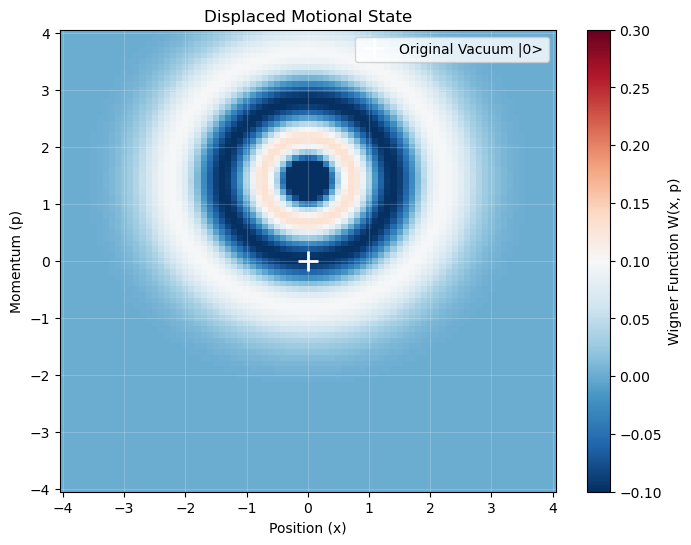

In [21]:
plot_wigner(noisy_beta_state)

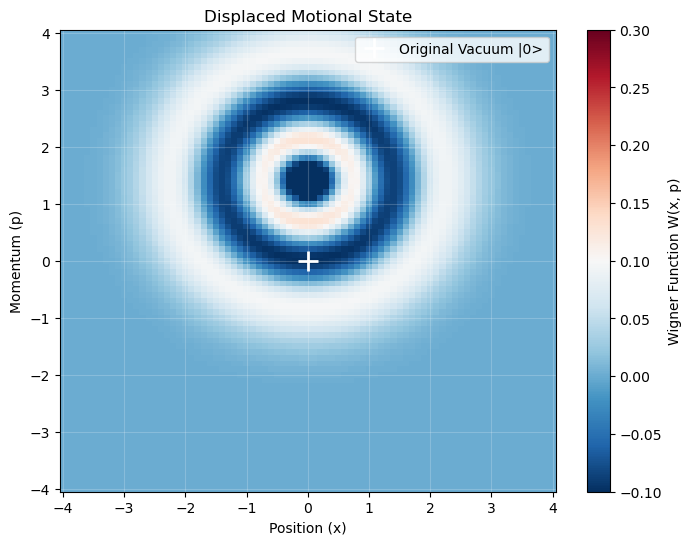

In [22]:

noisy_beta_state = SDF_apply_with_alpha_dephasing(1e3, 0.0, beta_signal, false, initial_sys_origin, 3, 10.0)
plot_wigner(noisy_beta_state)

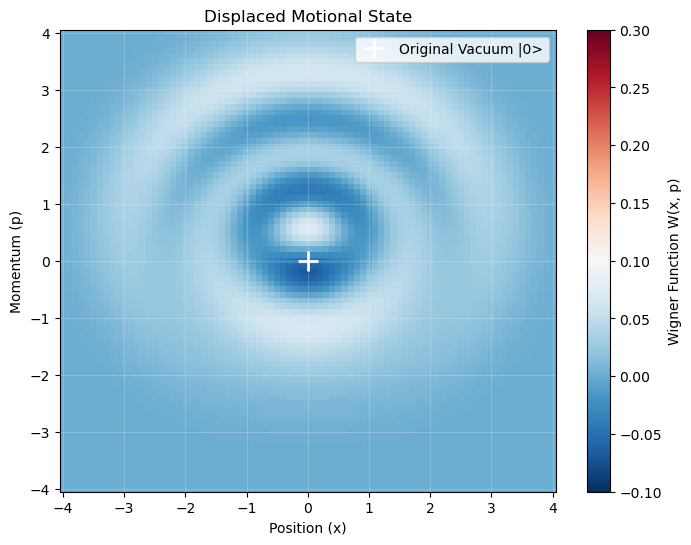

In [32]:

noisy_beta_state = SDF_apply_with_alpha_dephasing(1e3, 0.0, beta_signal, false, initial_sys_origin, 3, 1000.0)
plot_wigner(noisy_beta_state)

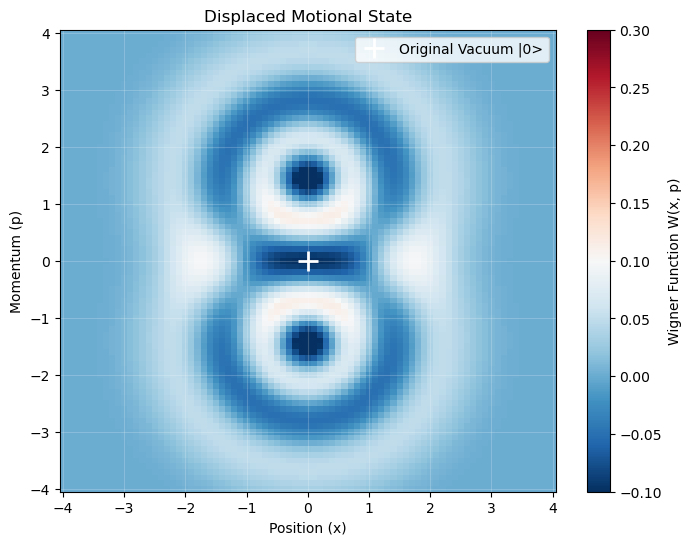

In [33]:

noisy_beta_state = SDF_apply_with_alpha_dephasing(1e3, 0.0, beta_signal, true, initial_sys_origin, 3, 1000.0)
plot_wigner(noisy_beta_state)

In [34]:
print(beta_signal)

1.0

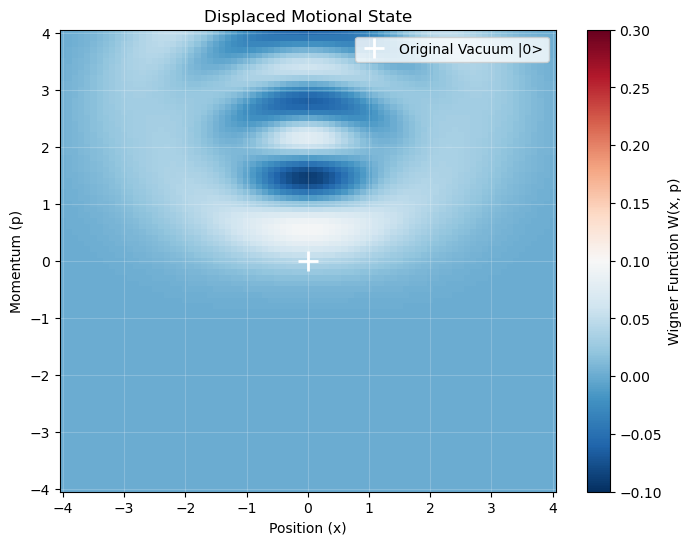

In [37]:

noisy_beta_state = SDF_apply_with_alpha_dephasing(1e3, 0.0, 2.0, false, initial_sys_origin, 3, 100.0)
plot_wigner(noisy_beta_state)

 EXPANDED MACROSCOPIC β=2.0 ANALYSIS (Fock n = 0 to 6)

Computed Asymptotic Prefactors (Γ_ϕ * t_sig -> ∞):
  Fock n=0 : K_n = 0.1699 | log10(K_n) = -0.7698
  Fock n=1 : K_n = 0.0937 | log10(K_n) = -1.0282
  Fock n=2 : K_n = 0.074 | log10(K_n) = -1.1307
  Fock n=3 : K_n = 0.0641 | log10(K_n) = -1.1932
  Fock n=4 : K_n = 0.0578 | log10(K_n) = -1.2379
  Fock n=5 : K_n = 0.0534 | log10(K_n) = -1.2725
  Fock n=6 : K_n = 0.05 | log10(K_n) = -1.3008


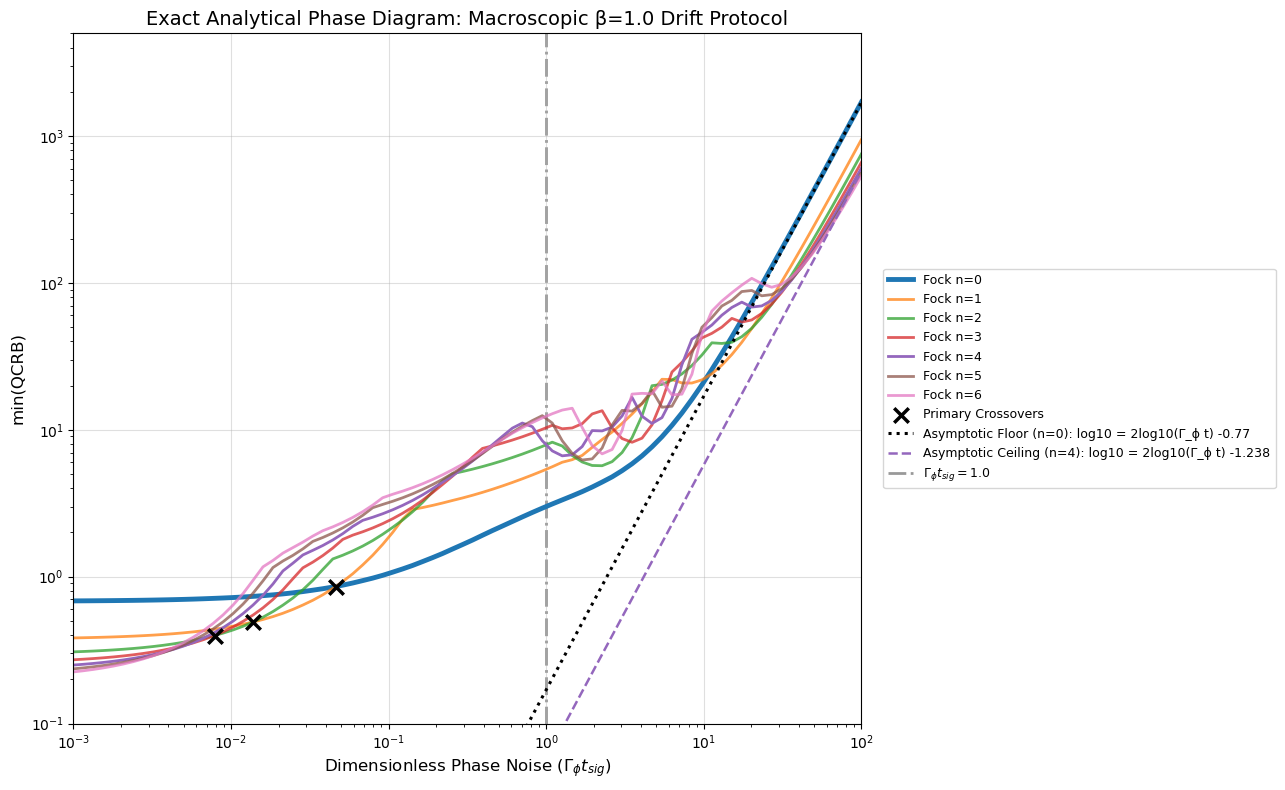

In [40]:
ENV["MPLBACKEND"] = "agg"
using PyPlot
using QuantumOptics
using IonSim

# -------------------------------------------------------------
# Exact Dynamic Signal Trajectory Integration
# -------------------------------------------------------------
function get_exact_beta_eff(beta_target::Float64, Gamma_t::Float64)
    if Gamma_t < 1e-5
        return beta_target / sqrt(3.0)
    end
    
    x = Gamma_t / 2.0
    term1 = 1.0
    term2 = (2.0 / x) * (exp(-x) - 1.0)
    term3 = -(1.0 / (2.0 * x)) * (exp(-2.0 * x) - 1.0)
    
    avg_sq = (beta_target^2 / x^2) * (term1 + term2 + term3)
    return sqrt(max(0.0, avg_sq))
end

# -------------------------------------------------------------
# Exact Numerical Ancilla QCRB (Macroscopic β=1.0 Drift Protocol)
# -------------------------------------------------------------
function get_dephased_ancilla_qcrb(n_fock::Int, Gamma_t::Float64)
    N_cut = 80 
    b = FockBasis(N_cut)
    
    # Continuous phase drag factor from the beta drive
    continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0

    # 1. Calculate the EXACT friction-damped effective radius
    beta_eff = get_exact_beta_eff(2.0, Gamma_t)
    
    psi_initial = fockstate(b, n_fock)
    
    # 2. Displace wavepacket to the dynamic effective radius BEFORE applying noise
    D_beta = displace(b, beta_eff)
    rho_displaced = dm(D_beta * psi_initial)
    
    # 3. Apply pure dephasing analytically in the Fock basis at this protected distance
    rho_dephased = deepcopy(rho_displaced)
    for i in 1:(N_cut + 1)
        for j in 1:(N_cut + 1)
            n_i = i - 1
            n_j = j - 1
            rho_dephased.data[i, j] *= exp(-0.5 * Gamma_t * (n_i - n_j)^2)
        end
    end
    
    # 4. Shift the smeared state back to the origin frame for the instantaneous α readout
    D_beta_inv = displace(b, -beta_eff)
    rho_readout_frame = D_beta_inv * rho_dephased * D_beta
    
    alpha_sweep = range(0.05, stop=4.0, length=140)
    min_qcrb = Inf
    
    for alpha in alpha_sweep
        # Instantaneous SDF split overlap (Eq 53) evaluated over the degraded state
        V_op = displace(b, -2.0 * alpha)
        V_val = real(expect(V_op, rho_readout_frame))
        
        if abs(V_val) > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * (continuous_signal_factor^2) * V_val^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
            end
        end
    end
    return min_qcrb
end

# -------------------------------------------------------------
# Analytical Infinite-Noise Coefficient K_n (Γ_ϕ * t_sig -> ∞)
# -------------------------------------------------------------
function get_asymptotic_prefactor_K(n_fock::Int)
    N_cut = 80
    b = FockBasis(N_cut)
    psi_initial = fockstate(b, n_fock)
    
    # In the infinite noise limit, continuous Zeno friction completely stalls the drive.
    # The effective radius is pinned at the origin (β_eff = 0).
    beta_eff = 0.0
    psi_disp = displace(b, beta_eff) * psi_initial
    
    alpha_sweep = range(0.05, stop=4.0, length=350)
    min_K = Inf

    for alpha in alpha_sweep
        V_op = displace(b, -2.0 * alpha)
        
        V_inf = 0.0
        for j in 1:(N_cut + 1)
            # Probability distribution of the state pinned at the origin
            prob_j = abs2(psi_disp.data[j]) 
            
            V_inf += prob_j * real(V_op.data[j, j])
        end
        
        if abs(V_inf) > 1e-10
            K_val = 1.0 / (64.0 * alpha^2 * V_inf^2)
            if K_val < min_K
                min_K = K_val
            end
        end
    end
    return min_K
end

# -------------------------------------------------------------
# Multi-Root Bracketed Logarithmic Bisection Finder
# -------------------------------------------------------------
function find_all_crossovers(n1::Int, n2::Int, grid::Vector{Float64}, qcrb1::Vector{Float64}, qcrb2::Vector{Float64}; tol=1e-5)
    f(g) = get_dephased_ancilla_qcrb(n1, g) - get_dephased_ancilla_qcrb(n2, g)
    roots = Tuple{Float64, Float64}[]

    for i in 1:(length(grid) - 1)
        val_min = qcrb1[i] - qcrb2[i]
        val_max = qcrb1[i+1] - qcrb2[i+1]

        if sign(val_min) != sign(val_max)
            g_min, g_max = grid[i], grid[i+1]
            g_mid = g_min
            for _ in 1:35
                g_mid = 10.0^((log10(g_min) + log10(g_max)) / 2.0)
                val_mid = f(g_mid)
                if abs(val_mid) < tol || abs(g_max - g_min) < tol
                    break
                end
                if sign(val_mid) == sign(val_min)
                    g_min = g_mid
                    val_min = val_mid
                else
                    g_max = g_mid
                    val_max = val_mid
                end
            end
            push!(roots, (g_mid, get_dephased_ancilla_qcrb(n1, g_mid)))
        end
    end
    return roots
end

# -------------------------------------------------------------
# Macroscopic β=1.0 Pure Dephasing Phase Diagram
# -------------------------------------------------------------
function plot_numerical_dephasing_crossover_expanded(laser_intensity::Float64=1e3)
    n_vals = [0, 1, 2, 3, 4, 5, 6]
    g_min_sweep = 1e-3  
    g_max_sweep = 1e2   
    gamma_t_sweep = 10.0 .^ range(log10(g_min_sweep), log10(g_max_sweep), length=80)
    
    state_colors = Dict(0=>"C0", 1=>"C1", 2=>"C2", 3=>"C3", 4=>"C4", 5=>"C5", 6=>"C6")

    trap_freq = 19e5; hbar = 1.0545718e-34; amu = 1.66053906e-27; m_Ca40 = 39.96259 * amu
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    z_zpf = sqrt(hbar / (2 * m_Ca40 * 2 * π * trap_freq))
    eta = ((2 * π / transition_λ) / sqrt(2)) * z_zpf
    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=transition_λ)
    Omega_eff = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0)) * 2 * π
    t_sig_s = 2.0 / (eta * Omega_eff)

    fig = figure(figsize=(13, 8))
    println("==========================================================")
    println(" EXPANDED MACROSCOPIC β=2.0 ANALYSIS (Fock n = 0 to 6)")
    println("==========================================================")

    qcrb_dict = Dict{Int, Vector{Float64}}()
    for n in n_vals
        qcrb_dict[n] = [get_dephased_ancilla_qcrb(n, gt) for gt in gamma_t_sweep]
        lw = n == 0  ? 3.5 : 2.0
        alpha_val = n == 0 || n == 4 ? 1.0 : 0.75
        plot(gamma_t_sweep, qcrb_dict[n], color=state_colors[n], linewidth=lw, alpha=alpha_val, label="Fock n=$n", zorder=2)
    end

    crossovers_to_find = [(3, 2), (2, 1), (1, 0)]
    primary_x = Float64[]; primary_y = Float64[]
    for (nA, nB) in crossovers_to_find
        roots = find_all_crossovers(nA, nB, gamma_t_sweep, qcrb_dict[nA], qcrb_dict[nB])
        if !isempty(roots)
            push!(primary_x, roots[1][1]); push!(primary_y, roots[1][2])
        end
    end
    scatter(primary_x, primary_y, color="black", s=110, zorder=5, marker="x", linewidths=2.5, label="Primary Crossovers")

    K0 = get_asymptotic_prefactor_K(0)
    K4 = get_asymptotic_prefactor_K(4)
    plot(gamma_t_sweep, K0 .* (gamma_t_sweep .^ 2), "k:", linewidth=2.2, zorder=3,
         label="Asymptotic Floor (n=0): log10 = 2log10(Γ_ϕ t) $(round(log10(K0), digits=3))")
    plot(gamma_t_sweep, K4 .* (gamma_t_sweep .^ 2), color="C4", linestyle="--", linewidth=1.8, zorder=3,
         label="Asymptotic Ceiling (n=4): log10 = 2log10(Γ_ϕ t) $(round(log10(K4), digits=3))")

    println("\nComputed Asymptotic Prefactors (Γ_ϕ * t_sig -> ∞):")
    for n in n_vals
        Kn = get_asymptotic_prefactor_K(n)
        println("  Fock n=$n : K_n = $(round(Kn, digits=4)) | log10(K_n) = $(round(log10(Kn), digits=4))")
    end
    println("==========================================================")

    axvline(x=1.0, color="gray", linestyle="-.", linewidth=2.0, alpha=0.8, label=L"\Gamma_\phi t_{sig} = 1.0", zorder=1)

    xscale("log"); yscale("log")
    xlim(g_min_sweep, g_max_sweep)
    ylim(1e-1, 5e3)

    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Exact Analytical Phase Diagram: Macroscopic β=1.0 Drift Protocol", fontsize=14)
    grid(alpha=0.4)
    legend(fontsize=9.0, loc="center left", bbox_to_anchor=(1.02, 0.5))
    tight_layout()

    display(fig)
end

plot_numerical_dephasing_crossover_expanded(1e3)

 EXPANDED MACROSCOPIC β=2.0 ANALYSIS (Fock n = 0 to 6)

Computed Asymptotic Prefactors (Γ_ϕ * t_sig -> ∞):
  Fock n=0 : K_n = 0.1699 | log10(K_n) = -0.7698
  Fock n=1 : K_n = 0.0937 | log10(K_n) = -1.0282
  Fock n=2 : K_n = 0.074 | log10(K_n) = -1.1307
  Fock n=3 : K_n = 0.0641 | log10(K_n) = -1.1932


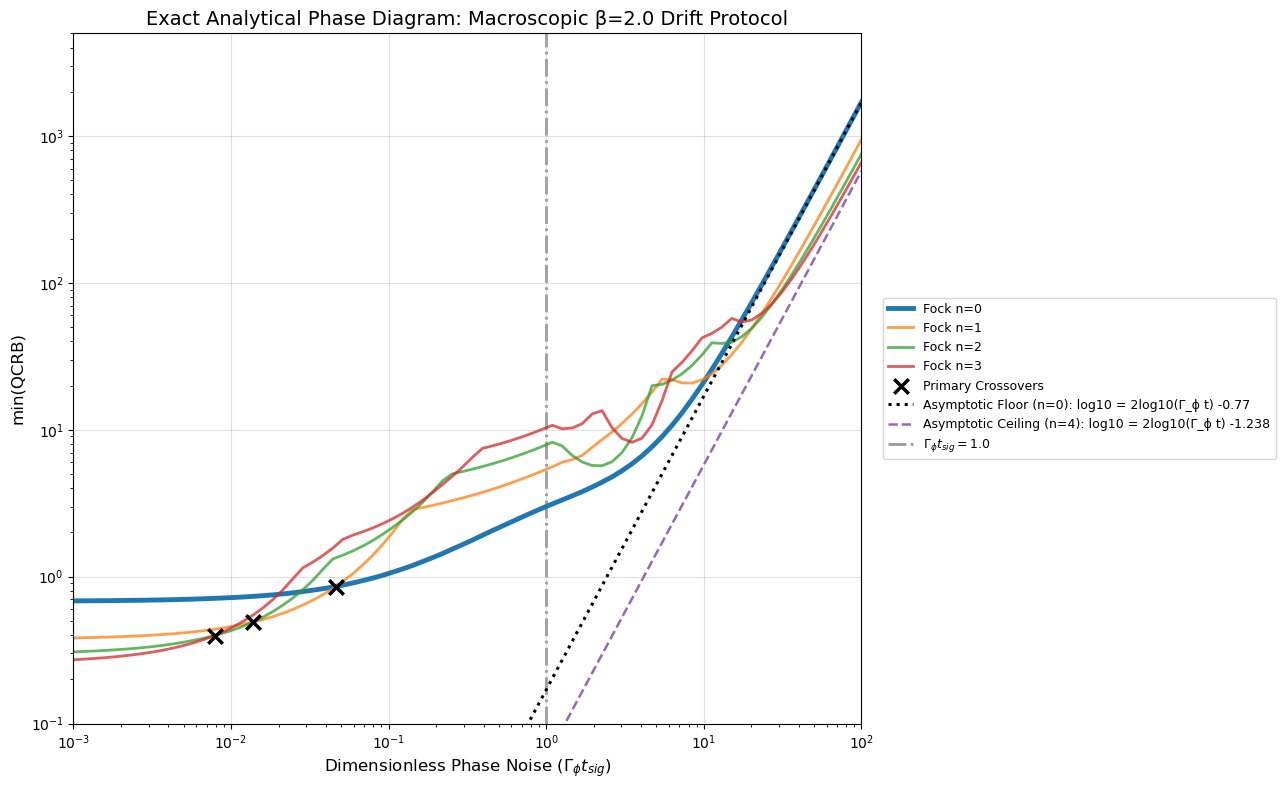

In [41]:
ENV["MPLBACKEND"] = "agg"
using PyPlot
using QuantumOptics
using IonSim

# -------------------------------------------------------------
# Exact Dynamic Signal Trajectory Integration
# -------------------------------------------------------------
function get_exact_beta_eff(beta_target::Float64, Gamma_t::Float64)
    if Gamma_t < 1e-5
        return beta_target / sqrt(3.0)
    end
    
    x = Gamma_t / 2.0
    term1 = 1.0
    term2 = (2.0 / x) * (exp(-x) - 1.0)
    term3 = -(1.0 / (2.0 * x)) * (exp(-2.0 * x) - 1.0)
    
    avg_sq = (beta_target^2 / x^2) * (term1 + term2 + term3)
    return sqrt(max(0.0, avg_sq))
end

# -------------------------------------------------------------
# Exact Numerical Ancilla QCRB (Macroscopic β=1.0 Drift Protocol)
# -------------------------------------------------------------
function get_dephased_ancilla_qcrb(n_fock::Int, Gamma_t::Float64)
    N_cut = 80 
    b = FockBasis(N_cut)
    
    # Continuous phase drag factor from the beta drive
    continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0

    # 1. Calculate the EXACT friction-damped effective radius
    beta_eff = get_exact_beta_eff(2.0, Gamma_t)
    
    psi_initial = fockstate(b, n_fock)
    
    # 2. Displace wavepacket to the dynamic effective radius BEFORE applying noise
    D_beta = displace(b, beta_eff)
    rho_displaced = dm(D_beta * psi_initial)
    
    # 3. Apply pure dephasing analytically in the Fock basis at this protected distance
    rho_dephased = deepcopy(rho_displaced)
    for i in 1:(N_cut + 1)
        for j in 1:(N_cut + 1)
            n_i = i - 1
            n_j = j - 1
            rho_dephased.data[i, j] *= exp(-0.5 * Gamma_t * (n_i - n_j)^2)
        end
    end
    
    # 4. Shift the smeared state back to the origin frame for the instantaneous α readout
    D_beta_inv = displace(b, -beta_eff)
    rho_readout_frame = D_beta_inv * rho_dephased * D_beta
    
    alpha_sweep = range(0.05, stop=4.0, length=140)
    min_qcrb = Inf
    
    for alpha in alpha_sweep
        # Instantaneous SDF split overlap (Eq 53) evaluated over the degraded state
        V_op = displace(b, -2.0 * alpha)
        V_val = real(expect(V_op, rho_readout_frame))
        
        if abs(V_val) > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * (continuous_signal_factor^2) * V_val^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
            end
        end
    end
    return min_qcrb
end

# -------------------------------------------------------------
# Analytical Infinite-Noise Coefficient K_n (Γ_ϕ * t_sig -> ∞)
# -------------------------------------------------------------
function get_asymptotic_prefactor_K(n_fock::Int)
    N_cut = 80
    b = FockBasis(N_cut)
    psi_initial = fockstate(b, n_fock)
    
    # In the infinite noise limit, continuous Zeno friction completely stalls the drive.
    # The effective radius is pinned at the origin (β_eff = 0).
    beta_eff = 0.0
    psi_disp = displace(b, beta_eff) * psi_initial
    
    alpha_sweep = range(0.05, stop=4.0, length=350)
    min_K = Inf

    for alpha in alpha_sweep
        V_op = displace(b, -2.0 * alpha)
        
        V_inf = 0.0
        for j in 1:(N_cut + 1)
            # Probability distribution of the state pinned at the origin
            prob_j = abs2(psi_disp.data[j]) 
            
            V_inf += prob_j * real(V_op.data[j, j])
        end
        
        if abs(V_inf) > 1e-10
            K_val = 1.0 / (64.0 * alpha^2 * V_inf^2)
            if K_val < min_K
                min_K = K_val
            end
        end
    end
    return min_K
end

# -------------------------------------------------------------
# Multi-Root Bracketed Logarithmic Bisection Finder
# -------------------------------------------------------------
function find_all_crossovers(n1::Int, n2::Int, grid::Vector{Float64}, qcrb1::Vector{Float64}, qcrb2::Vector{Float64}; tol=1e-5)
    f(g) = get_dephased_ancilla_qcrb(n1, g) - get_dephased_ancilla_qcrb(n2, g)
    roots = Tuple{Float64, Float64}[]

    for i in 1:(length(grid) - 1)
        val_min = qcrb1[i] - qcrb2[i]
        val_max = qcrb1[i+1] - qcrb2[i+1]

        if sign(val_min) != sign(val_max)
            g_min, g_max = grid[i], grid[i+1]
            g_mid = g_min
            for _ in 1:35
                g_mid = 10.0^((log10(g_min) + log10(g_max)) / 2.0)
                val_mid = f(g_mid)
                if abs(val_mid) < tol || abs(g_max - g_min) < tol
                    break
                end
                if sign(val_mid) == sign(val_min)
                    g_min = g_mid
                    val_min = val_mid
                else
                    g_max = g_mid
                    val_max = val_mid
                end
            end
            push!(roots, (g_mid, get_dephased_ancilla_qcrb(n1, g_mid)))
        end
    end
    return roots
end

# -------------------------------------------------------------
# Macroscopic β=1.0 Pure Dephasing Phase Diagram
# -------------------------------------------------------------
function plot_numerical_dephasing_crossover_expanded(laser_intensity::Float64=1e3)
    n_vals = [0, 1, 2, 3]
    g_min_sweep = 1e-3  
    g_max_sweep = 1e2   
    gamma_t_sweep = 10.0 .^ range(log10(g_min_sweep), log10(g_max_sweep), length=80)
    
    state_colors = Dict(0=>"C0", 1=>"C1", 2=>"C2", 3=>"C3")

    trap_freq = 19e5; hbar = 1.0545718e-34; amu = 1.66053906e-27; m_Ca40 = 39.96259 * amu
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    z_zpf = sqrt(hbar / (2 * m_Ca40 * 2 * π * trap_freq))
    eta = ((2 * π / transition_λ) / sqrt(2)) * z_zpf
    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=transition_λ)
    Omega_eff = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0)) * 2 * π
    t_sig_s = 2.0 / (eta * Omega_eff)

    fig = figure(figsize=(13, 8))
    println("==========================================================")
    println(" EXPANDED MACROSCOPIC β=2.0 ANALYSIS (Fock n = 0 to 6)")
    println("==========================================================")

    qcrb_dict = Dict{Int, Vector{Float64}}()
    for n in n_vals
        qcrb_dict[n] = [get_dephased_ancilla_qcrb(n, gt) for gt in gamma_t_sweep]
        lw = n == 0  ? 3.5 : 2.0
        alpha_val = n == 0 || n == 4 ? 1.0 : 0.75
        plot(gamma_t_sweep, qcrb_dict[n], color=state_colors[n], linewidth=lw, alpha=alpha_val, label="Fock n=$n", zorder=2)
    end

    crossovers_to_find = [(3, 2), (2, 1), (1, 0)]
    primary_x = Float64[]; primary_y = Float64[]
    for (nA, nB) in crossovers_to_find
        roots = find_all_crossovers(nA, nB, gamma_t_sweep, qcrb_dict[nA], qcrb_dict[nB])
        if !isempty(roots)
            push!(primary_x, roots[1][1]); push!(primary_y, roots[1][2])
        end
    end
    scatter(primary_x, primary_y, color="black", s=110, zorder=5, marker="x", linewidths=2.5, label="Primary Crossovers")

    K0 = get_asymptotic_prefactor_K(0)
    K4 = get_asymptotic_prefactor_K(4)
    plot(gamma_t_sweep, K0 .* (gamma_t_sweep .^ 2), "k:", linewidth=2.2, zorder=3,
         label="Asymptotic Floor (n=0): log10 = 2log10(Γ_ϕ t) $(round(log10(K0), digits=3))")
    plot(gamma_t_sweep, K4 .* (gamma_t_sweep .^ 2), color="C4", linestyle="--", linewidth=1.8, zorder=3,
         label="Asymptotic Ceiling (n=4): log10 = 2log10(Γ_ϕ t) $(round(log10(K4), digits=3))")

    println("\nComputed Asymptotic Prefactors (Γ_ϕ * t_sig -> ∞):")
    for n in n_vals
        Kn = get_asymptotic_prefactor_K(n)
        println("  Fock n=$n : K_n = $(round(Kn, digits=4)) | log10(K_n) = $(round(log10(Kn), digits=4))")
    end
    println("==========================================================")

    axvline(x=1.0, color="gray", linestyle="-.", linewidth=2.0, alpha=0.8, label=L"\Gamma_\phi t_{sig} = 1.0", zorder=1)

    xscale("log"); yscale("log")
    xlim(g_min_sweep, g_max_sweep)
    ylim(1e-1, 5e3)

    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Exact Analytical Phase Diagram: Macroscopic β=2.0 Drift Protocol", fontsize=14)
    grid(alpha=0.4)
    legend(fontsize=9.0, loc="center left", bbox_to_anchor=(1.02, 0.5))
    tight_layout()

    display(fig)
end

plot_numerical_dephasing_crossover_expanded(1e3)

 EXACT TROTTER PHASE DIAGRAM: Macroscopic β=2.0
Evaluating Trotter limits for Fock n=0 ...
Evaluating Trotter limits for Fock n=1 ...
Evaluating Trotter limits for Fock n=2 ...
Evaluating Trotter limits for Fock n=3 ...
Evaluating Trotter limits for Fock n=4 ...
Evaluating Trotter limits for Fock n=5 ...
Evaluating Trotter limits for Fock n=6 ...


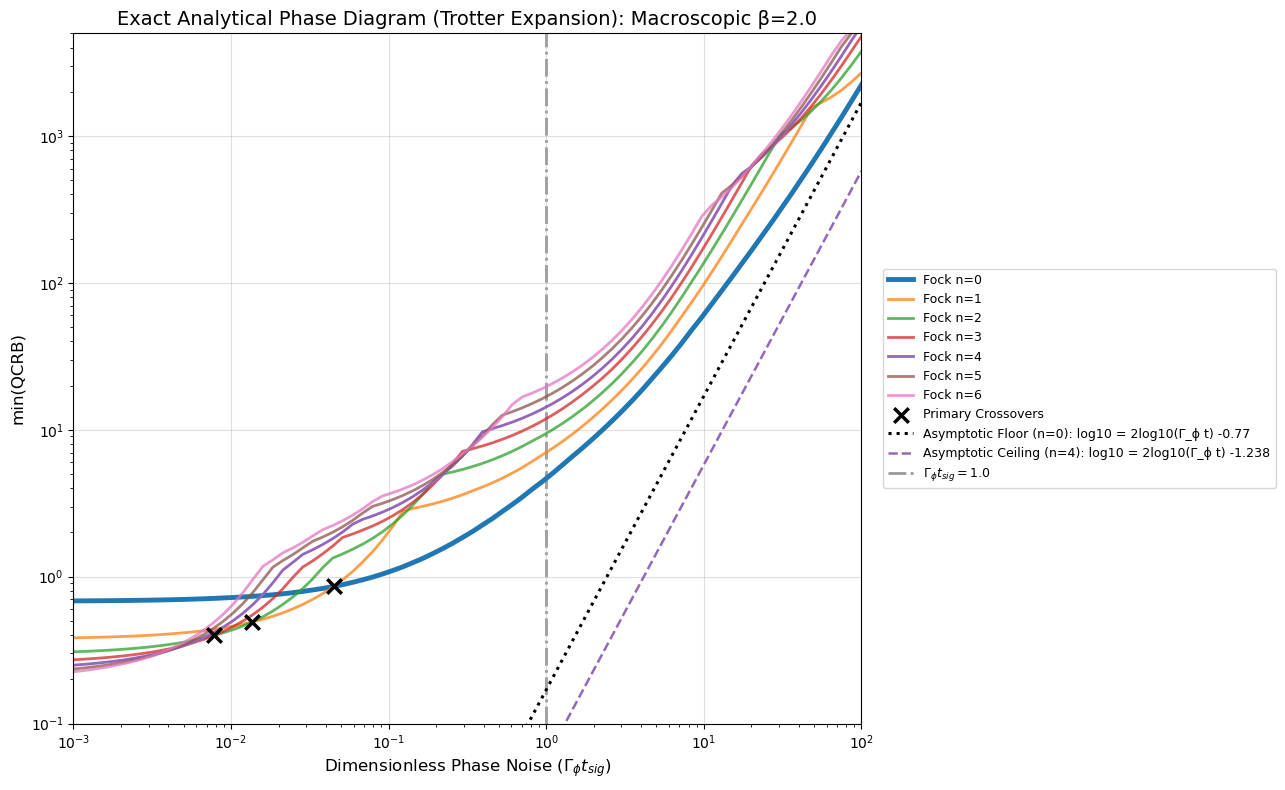

In [42]:
ENV["MPLBACKEND"] = "agg"
using QuantumOptics
using PyPlot

# -------------------------------------------------------------
# Step-by-Step Analytical Open System (Trotterization)
# -------------------------------------------------------------
function get_stepwise_open_theory_rho(n_fock::Int, Gamma_t::Float64, beta_target::Float64, steps::Int=400)
    N_cut = 60 
    b = FockBasis(N_cut)
    rho = dm(fockstate(b, n_fock))
    
    delta_beta = beta_target / steps
    delta_gamma = Gamma_t / steps
    
    D_step = displace(b, delta_beta)
    D_step_dag = dagger(D_step)
    
    for k in 1:steps
        # 1. Apply differential coherent signal drive
        rho = D_step * rho * D_step_dag
        
        # 2. Apply differential pure dephasing in the Fock basis
        for i in 1:(N_cut + 1)
            for j in 1:(N_cut + 1)
                rho.data[i, j] *= exp(-0.5 * delta_gamma * ((i - 1) - (j - 1))^2)
            end
        end
    end
    return rho
end

# -------------------------------------------------------------
# Fast Exact Trotter QCRB (Bypasses Eigenvalue Solver)
# -------------------------------------------------------------
function get_trotter_ancilla_qcrb(n_fock::Int, Gamma_t::Float64, beta_target::Float64)
    N_cut = 60 
    b = FockBasis(N_cut)
    
    continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0
    
    # Evolve the state using the exact continuous Trotter dynamics
    rho_motional = get_stepwise_open_theory_rho(n_fock, Gamma_t, beta_target)
    
    alpha_sweep = range(0.05, stop=4.0, length=150)
    min_qcrb = Inf
    
    for alpha in alpha_sweep
        V_op = displace(b, -2.0 * alpha)
        
        # V_open is exactly the absolute value of the characteristic function overlap
        V_val = abs(expect(V_op, rho_motional))
        
        if V_val > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * (continuous_signal_factor^2) * V_val^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
            end
        end
    end
    return min_qcrb
end

# -------------------------------------------------------------
# Analytical Infinite-Noise Coefficient K_n (Γ_ϕ * t_sig -> ∞)
# -------------------------------------------------------------
function get_asymptotic_prefactor_K(n_fock::Int)
    N_cut = 80
    b = FockBasis(N_cut)
    psi_initial = fockstate(b, n_fock)
    
    # Infinite Zeno friction pins the effective radius to the origin
    beta_eff = 0.0
    psi_disp = displace(b, beta_eff) * psi_initial
    
    alpha_sweep = range(0.05, stop=4.0, length=350)
    min_K = Inf

    for alpha in alpha_sweep
        V_op = displace(b, -2.0 * alpha)
        
        V_inf = 0.0
        for j in 1:(N_cut + 1)
            prob_j = abs2(psi_disp.data[j]) 
            V_inf += prob_j * real(V_op.data[j, j])
        end
        
        if abs(V_inf) > 1e-10
            K_val = 1.0 / (64.0 * alpha^2 * V_inf^2)
            if K_val < min_K
                min_K = K_val
            end
        end
    end
    return min_K
end

# -------------------------------------------------------------
# Multi-Root Bracketed Logarithmic Bisection Finder
# -------------------------------------------------------------
function find_all_crossovers(n1::Int, n2::Int, grid::Vector{Float64}, qcrb1::Vector{Float64}, qcrb2::Vector{Float64}, beta_target::Float64; tol=1e-5)
    f(g) = get_trotter_ancilla_qcrb(n1, g, beta_target) - get_trotter_ancilla_qcrb(n2, g, beta_target)
    roots = Tuple{Float64, Float64}[]

    for i in 1:(length(grid) - 1)
        val_min = qcrb1[i] - qcrb2[i]
        val_max = qcrb1[i+1] - qcrb2[i+1]

        if sign(val_min) != sign(val_max)
            g_min, g_max = grid[i], grid[i+1]
            g_mid = g_min
            for _ in 1:35
                g_mid = 10.0^((log10(g_min) + log10(g_max)) / 2.0)
                val_mid = f(g_mid)
                if abs(val_mid) < tol || abs(g_max - g_min) < tol
                    break
                end
                if sign(val_mid) == sign(val_min)
                    g_min = g_mid
                    val_min = val_mid
                else
                    g_max = g_mid
                    val_max = val_mid
                end
            end
            push!(roots, (g_mid, get_trotter_ancilla_qcrb(n1, g_mid, beta_target)))
        end
    end
    return roots
end

# -------------------------------------------------------------
# Exact Trotter Phase Diagram
# -------------------------------------------------------------
function plot_exact_trotter_phase_diagram(beta_signal::Float64=2.0)
    n_vals = [0, 1, 2, 3, 4, 5, 6]
    g_min_sweep = 1e-3  
    g_max_sweep = 1e2   
    gamma_t_sweep = 10.0 .^ range(log10(g_min_sweep), log10(g_max_sweep), length=80)
    
    state_colors = Dict(0=>"C0", 1=>"C1", 2=>"C2", 3=>"C3", 4=>"C4", 5=>"C5", 6=>"C6")

    fig = figure(figsize=(13, 8))
    println("==========================================================")
    println(" EXACT TROTTER PHASE DIAGRAM: Macroscopic β=$(beta_signal)")
    println("==========================================================")

    qcrb_dict = Dict{Int, Vector{Float64}}()
    for n in n_vals
        println("Evaluating Trotter limits for Fock n=$n ...")
        qcrb_dict[n] = [get_trotter_ancilla_qcrb(n, gt, beta_signal) for gt in gamma_t_sweep]
        lw = n == 0  ? 3.5 : 2.0
        alpha_val = n == 0 || n == 4 ? 1.0 : 0.75
        plot(gamma_t_sweep, qcrb_dict[n], color=state_colors[n], linewidth=lw, alpha=alpha_val, label="Fock n=$n", zorder=2)
    end

    crossovers_to_find = [(3, 2), (2, 1), (1, 0)]
    primary_x = Float64[]; primary_y = Float64[]
    for (nA, nB) in crossovers_to_find
        roots = find_all_crossovers(nA, nB, gamma_t_sweep, qcrb_dict[nA], qcrb_dict[nB], beta_signal)
        if !isempty(roots)
            push!(primary_x, roots[1][1]); push!(primary_y, roots[1][2])
        end
    end
    scatter(primary_x, primary_y, color="black", s=110, zorder=5, marker="x", linewidths=2.5, label="Primary Crossovers")

    K0 = get_asymptotic_prefactor_K(0)
    K4 = get_asymptotic_prefactor_K(4)
    plot(gamma_t_sweep, K0 .* (gamma_t_sweep .^ 2), "k:", linewidth=2.2, zorder=3,
         label="Asymptotic Floor (n=0): log10 = 2log10(Γ_ϕ t) $(round(log10(K0), digits=3))")
    plot(gamma_t_sweep, K4 .* (gamma_t_sweep .^ 2), color="C4", linestyle="--", linewidth=1.8, zorder=3,
         label="Asymptotic Ceiling (n=4): log10 = 2log10(Γ_ϕ t) $(round(log10(K4), digits=3))")

    axvline(x=1.0, color="gray", linestyle="-.", linewidth=2.0, alpha=0.8, label=L"\Gamma_\phi t_{sig} = 1.0", zorder=1)

    xscale("log"); yscale("log")
    xlim(g_min_sweep, g_max_sweep)
    ylim(1e-1, 5e3)

    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Exact Analytical Phase Diagram (Trotter Expansion): Macroscopic β=$(beta_signal)", fontsize=14)
    grid(alpha=0.4)
    legend(fontsize=9.0, loc="center left", bbox_to_anchor=(1.02, 0.5))
    tight_layout()

    display(fig)
end

plot_exact_trotter_phase_diagram(2.0)

 EXACT TROTTER PHASE DIAGRAM: Macroscopic β=2.0
Physical Parameters:
  Laser Intensity (I)  = 1000.0 W/m^2
  Exposure Time (t_sig)= 0.004413 s
----------------------------------------------------------
Evaluating Trotter limits for Fock n=0 ...
Evaluating Trotter limits for Fock n=1 ...
Evaluating Trotter limits for Fock n=2 ...
Evaluating Trotter limits for Fock n=3 ...
Evaluating Trotter limits for Fock n=4 ...
Evaluating Trotter limits for Fock n=5 ...
Evaluating Trotter limits for Fock n=6 ...

Crossover Coordinates:
  n=3 vs n=2 -> Γ_ϕ t_sig = 0.0078, min(QCRB) = 0.3976
  n=2 vs n=1 -> Γ_ϕ t_sig = 0.0137, min(QCRB) = 0.4918
  n=1 vs n=0 -> Γ_ϕ t_sig = 0.0447, min(QCRB) = 0.857


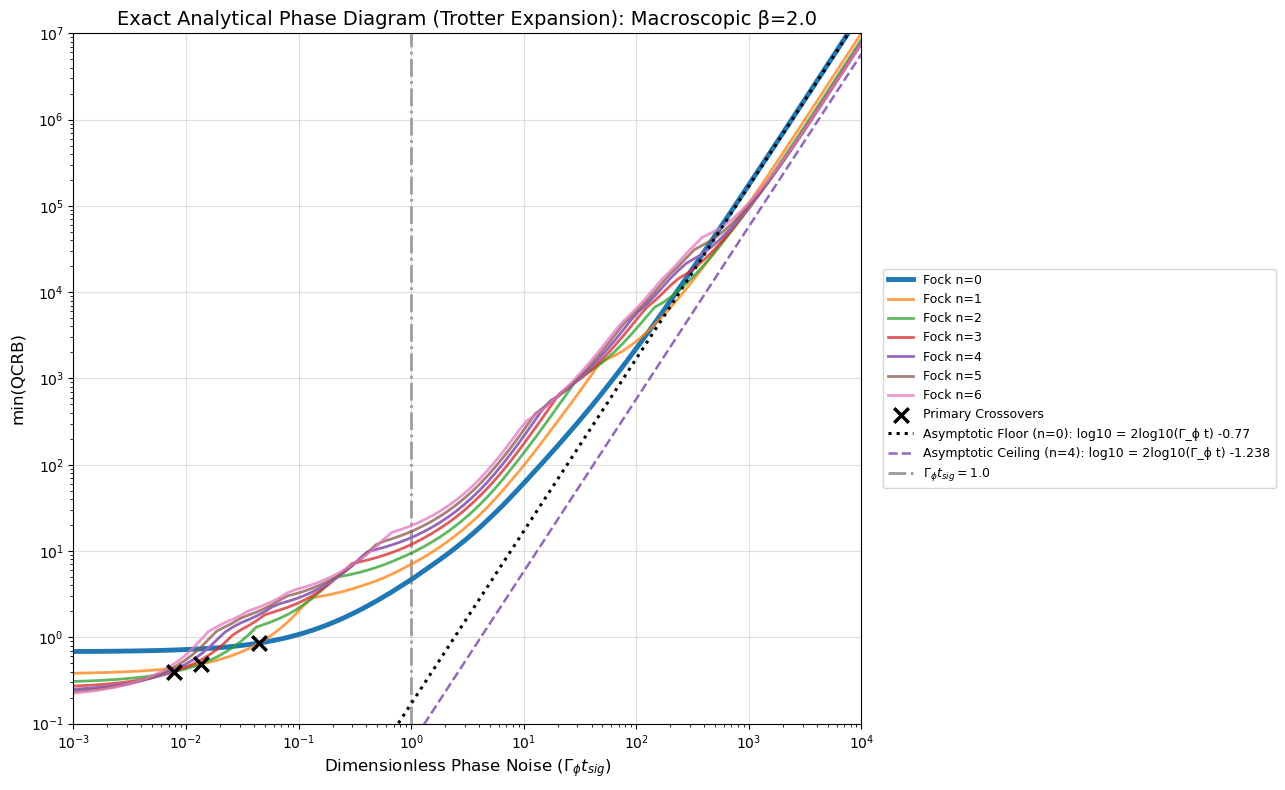

In [45]:
ENV["MPLBACKEND"] = "agg"
using IonSim
using QuantumOptics
using PyPlot

# -------------------------------------------------------------
# Step-by-Step Analytical Open System (Trotterization)
# -------------------------------------------------------------
function get_stepwise_open_theory_rho(n_fock::Int, Gamma_t::Float64, beta_target::Float64, steps::Int=400)
    N_cut = 60 
    b = FockBasis(N_cut)
    rho = dm(fockstate(b, n_fock))
    
    delta_beta = beta_target / steps
    delta_gamma = Gamma_t / steps
    
    D_step = displace(b, delta_beta)
    D_step_dag = dagger(D_step)
    
    for k in 1:steps
        # 1. Apply differential coherent signal drive
        rho = D_step * rho * D_step_dag
        
        # 2. Apply differential pure dephasing in the Fock basis
        for i in 1:(N_cut + 1)
            for j in 1:(N_cut + 1)
                rho.data[i, j] *= exp(-0.5 * delta_gamma * ((i - 1) - (j - 1))^2)
            end
        end
    end
    return rho
end

# -------------------------------------------------------------
# Fast Exact Trotter QCRB (Bypasses Eigenvalue Solver)
# -------------------------------------------------------------
function get_trotter_ancilla_qcrb(n_fock::Int, Gamma_t::Float64, beta_target::Float64)
    N_cut = 60 
    b = FockBasis(N_cut)
    
    continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0
    
    # Evolve the state using the exact continuous Trotter dynamics
    rho_motional = get_stepwise_open_theory_rho(n_fock, Gamma_t, beta_target)
    
    alpha_sweep = range(0.05, stop=4.0, length=150)
    min_qcrb = Inf
    
    for alpha in alpha_sweep
        V_op = displace(b, -2.0 * alpha)
        
        # V_open is exactly the absolute value of the characteristic function overlap
        V_val = abs(expect(V_op, rho_motional))
        
        if V_val > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * (continuous_signal_factor^2) * V_val^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
            end
        end
    end
    return min_qcrb
end

# -------------------------------------------------------------
# Analytical Infinite-Noise Coefficient K_n (Γ_ϕ * t_sig -> ∞)
# -------------------------------------------------------------
function get_asymptotic_prefactor_K(n_fock::Int)
    N_cut = 80
    b = FockBasis(N_cut)
    psi_initial = fockstate(b, n_fock)
    
    # Infinite Zeno friction pins the effective radius to the origin
    beta_eff = 0.0
    psi_disp = displace(b, beta_eff) * psi_initial
    
    alpha_sweep = range(0.05, stop=4.0, length=350)
    min_K = Inf

    for alpha in alpha_sweep
        V_op = displace(b, -2.0 * alpha)
        
        V_inf = 0.0
        for j in 1:(N_cut + 1)
            prob_j = abs2(psi_disp.data[j]) 
            V_inf += prob_j * real(V_op.data[j, j])
        end
        
        if abs(V_inf) > 1e-10
            K_val = 1.0 / (64.0 * alpha^2 * V_inf^2)
            if K_val < min_K
                min_K = K_val
            end
        end
    end
    return min_K
end

# -------------------------------------------------------------
# Multi-Root Bracketed Logarithmic Bisection Finder
# -------------------------------------------------------------
function find_all_crossovers(n1::Int, n2::Int, grid::Vector{Float64}, qcrb1::Vector{Float64}, qcrb2::Vector{Float64}, beta_target::Float64; tol=1e-5)
    f(g) = get_trotter_ancilla_qcrb(n1, g, beta_target) - get_trotter_ancilla_qcrb(n2, g, beta_target)
    roots = Tuple{Float64, Float64}[]

    for i in 1:(length(grid) - 1)
        val_min = qcrb1[i] - qcrb2[i]
        val_max = qcrb1[i+1] - qcrb2[i+1]

        if sign(val_min) != sign(val_max)
            g_min, g_max = grid[i], grid[i+1]
            g_mid = g_min
            for _ in 1:35
                g_mid = 10.0^((log10(g_min) + log10(g_max)) / 2.0)
                val_mid = f(g_mid)
                if abs(val_mid) < tol || abs(g_max - g_min) < tol
                    break
                end
                if sign(val_mid) == sign(val_min)
                    g_min = g_mid
                    val_min = val_mid
                else
                    g_max = g_mid
                    val_max = val_mid
                end
            end
            push!(roots, (g_mid, get_trotter_ancilla_qcrb(n1, g_mid, beta_target)))
        end
    end
    return roots
end

# -------------------------------------------------------------
# Exact Trotter Phase Diagram
# -------------------------------------------------------------
function plot_exact_trotter_phase_diagram(beta_signal::Float64=2.0, laser_intensity::Float64=1e3)
    # Calculate exact physical parameters
    trap_freq = 19e5; hbar = 1.0545718e-34; amu = 1.66053906e-27; m_Ca40 = 39.96259 * amu
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    eta = ((2 * π / transition_λ) / sqrt(2)) * sqrt(hbar / (2 * m_Ca40 * 2 * π * trap_freq))
    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=transition_λ)
    Omega_eff = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0)) * 2 * π
    
    t_sig_s = (2 * beta_signal) / (eta * Omega_eff)

    n_vals = [0, 1, 2, 3, 4, 5, 6]
    g_min_sweep = 1e-3  
    g_max_sweep = 1e4   # Expanded sweep range to show deep asymptotic regime
    gamma_t_sweep = 10.0 .^ range(log10(g_min_sweep), log10(g_max_sweep), length=100)
    
    state_colors = Dict(0=>"C0", 1=>"C1", 2=>"C2", 3=>"C3", 4=>"C4", 5=>"C5", 6=>"C6")

    fig = figure(figsize=(13, 8))
    println("==========================================================")
    println(" EXACT TROTTER PHASE DIAGRAM: Macroscopic β=$(beta_signal)")
    println("==========================================================")
    println("Physical Parameters:")
    println("  Laser Intensity (I)  = $(laser_intensity) W/m^2")
    println("  Exposure Time (t_sig)= $(round(t_sig_s, digits=6)) s")
    println("----------------------------------------------------------")

    qcrb_dict = Dict{Int, Vector{Float64}}()
    for n in n_vals
        println("Evaluating Trotter limits for Fock n=$n ...")
        qcrb_dict[n] = [get_trotter_ancilla_qcrb(n, gt, beta_signal) for gt in gamma_t_sweep]
        lw = n == 0  ? 3.5 : 2.0
        alpha_val = n == 0 || n == 4 ? 1.0 : 0.75
        plot(gamma_t_sweep, qcrb_dict[n], color=state_colors[n], linewidth=lw, alpha=alpha_val, label="Fock n=$n", zorder=2)
    end

    println("\nCrossover Coordinates:")
    crossovers_to_find = [(3, 2), (2, 1), (1, 0)]
    primary_x = Float64[]; primary_y = Float64[]
    for (nA, nB) in crossovers_to_find
        roots = find_all_crossovers(nA, nB, gamma_t_sweep, qcrb_dict[nA], qcrb_dict[nB], beta_signal)
        if !isempty(roots)
            gt_val = roots[1][1]
            qcrb_val = roots[1][2]
            push!(primary_x, gt_val); push!(primary_y, qcrb_val)
            println("  n=$nA vs n=$nB -> Γ_ϕ t_sig = $(round(gt_val, digits=4)), min(QCRB) = $(round(qcrb_val, digits=4))")
        end
    end
    scatter(primary_x, primary_y, color="black", s=110, zorder=5, marker="x", linewidths=2.5, label="Primary Crossovers")

    K0 = get_asymptotic_prefactor_K(0)
    K4 = get_asymptotic_prefactor_K(4)
    plot(gamma_t_sweep, K0 .* (gamma_t_sweep .^ 2), "k:", linewidth=2.2, zorder=3,
         label="Asymptotic Floor (n=0): log10 = 2log10(Γ_ϕ t) $(round(log10(K0), digits=3))")
    plot(gamma_t_sweep, K4 .* (gamma_t_sweep .^ 2), color="C4", linestyle="--", linewidth=1.8, zorder=3,
         label="Asymptotic Ceiling (n=4): log10 = 2log10(Γ_ϕ t) $(round(log10(K4), digits=3))")

    axvline(x=1.0, color="gray", linestyle="-.", linewidth=2.0, alpha=0.8, label=L"\Gamma_\phi t_{sig} = 1.0", zorder=1)

    xscale("log"); yscale("log")
    xlim(g_min_sweep, g_max_sweep)
    ylim(1e-1, 1e7) # Adjusted ylim to accommodate the expanded x-axis range

    xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ylabel("min(QCRB)", fontsize=12)
    title("Exact Analytical Phase Diagram (Trotter Expansion): Macroscopic β=$(beta_signal)", fontsize=14)
    grid(alpha=0.4)
    legend(fontsize=9.0, loc="center left", bbox_to_anchor=(1.02, 0.5))
    tight_layout()

    display(fig)
end

plot_exact_trotter_phase_diagram(2.0, 1e3)

In [ ]:
ENV["MPLBACKEND"] = "agg"
using QuantumOptics
using PyPlot

# -------------------------------------------------------------
# Step-by-Step Analytical Open System (Trotterization)
# -------------------------------------------------------------
function get_stepwise_open_theory_rho(n_fock::Int, Gamma_t::Float64, beta_target::Float64, steps::Int=400)
    N_cut = 60 
    b = FockBasis(N_cut)
    rho = dm(fockstate(b, n_fock))
    
    delta_beta = beta_target / steps
    delta_gamma = Gamma_t / steps
    
    D_step = displace(b, delta_beta)
    D_step_dag = dagger(D_step)
    
    for k in 1:steps
        rho = D_step * rho * D_step_dag
        for i in 1:(N_cut + 1)
            for j in 1:(N_cut + 1)
                rho.data[i, j] *= exp(-0.5 * delta_gamma * ((i - 1) - (j - 1))^2)
            end
        end
    end
    return rho
end

# -------------------------------------------------------------
# Extract Both QCRB and Optimal Alpha
# -------------------------------------------------------------
function get_trotter_qcrb_and_alpha(n_fock::Int, Gamma_t::Float64, beta_target::Float64)
    N_cut = 60 
    b = FockBasis(N_cut)
    
    continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0
    # Evolve the state using the exact continuous Trotter dynamics
    rho_motional = get_stepwise_open_theory_rho(n_fock, Gamma_t, beta_target)
    
    # NEW FIX: Find the actual drifted center and shift back to the readout frame
    a_op = destroy(b)
    beta_final = expect(a_op, rho_motional)
    D_shift = displace(b, -beta_final)
    rho_readout_frame = D_shift * rho_motional * dagger(D_shift)
    
    alpha_sweep = range(0.05, stop=4.0, length=150)
    min_qcrb = Inf
    opt_alpha = 0.0
    
    for alpha in alpha_sweep
        V_op = displace(b, -2.0 * alpha)
        
        # Evaluate overlap in the properly centered readout frame
        V_val = abs(expect(V_op, rho_readout_frame))
        
        if V_val > 1e-10
            qcrb = 1.0 / (16.0 * alpha^2 * (continuous_signal_factor^2) * V_val^2)
            if qcrb < min_qcrb
                min_qcrb = qcrb
                opt_alpha = alpha
            end
        end
    end
    return min_qcrb, opt_alpha
end

# -------------------------------------------------------------
# Plot QCRB and Alpha_opt Verification
# -------------------------------------------------------------
function plot_qcrb_and_alpha_verification(beta_signal::Float64=2.0)
    n_vals = [0, 1, 2, 3] # Focus on first few states for clarity
    g_min_sweep = 1e-2  
    g_max_sweep = 1e2   
    gamma_t_sweep = 10.0 .^ range(log10(g_min_sweep), log10(g_max_sweep), length=100)
    
    state_colors = Dict(0=>"C0", 1=>"C1", 2=>"C2", 3=>"C3")

    fig, (ax1, ax2) = subplots(2, 1, figsize=(11, 10), sharex=true, gridspec_kw=Dict("height_ratios" => [2, 1]))
    
    println("==========================================================")
    println(" EXTRACTING α_opt JUMPS vs SMOOTH BUMPS (β=$(beta_signal))")
    println("==========================================================")

    for n in n_vals
        println("Evaluating Trotter limits for Fock n=$n ...")
        results = [get_trotter_qcrb_and_alpha(n, gt, beta_signal) for gt in gamma_t_sweep]
        qcrbs = [r[1] for r in results]
        alphas = [r[2] for r in results]
        
        lw = n == 0 ? 3.5 : 2.0
        ax1.plot(gamma_t_sweep, qcrbs, color=state_colors[n], linewidth=lw, label="Fock n=$n")
        ax2.plot(gamma_t_sweep, alphas, "-", color=state_colors[n], linewidth=2.0, label="Fock n=$n")
        
        # Mark discontinuous alpha jumps (snaps) > 0.2
        for i in 2:length(alphas)
            if abs(alphas[i] - alphas[i-1]) > 0.2
                ax1.scatter([gamma_t_sweep[i]], [qcrbs[i]], color="black", s=100, zorder=5, marker="x")
                ax2.scatter([gamma_t_sweep[i]], [alphas[i]], color="black", s=100, zorder=5, marker="x")
                println("  -> SNAP DETECTED (n=$n): Γ_ϕ t_sig = $(round(gamma_t_sweep[i], digits=3)) | α snapped from $(round(alphas[i-1], digits=2)) to $(round(alphas[i], digits=2))")
            end
        end
    end

    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax1.set_ylim(1e-1, 1e4)
    ax1.set_ylabel("min(QCRB)", fontsize=12)
    ax1.set_title("Exact Analytical Phase Diagram vs Optimal Readout (β=$(beta_signal))", fontsize=14)
    ax1.grid(alpha=0.4)
    ax1.legend(fontsize=10, loc="upper left")

    ax2.set_xscale("log")
    ax2.set_ylim(0, 3.5)
    ax2.set_xlabel(L"Dimensionless Phase Noise $(\Gamma_\phi t_{sig})$", fontsize=12)
    ax2.set_ylabel(L"Optimal Readout $\alpha_{opt}$", fontsize=12)
    ax2.grid(alpha=0.4)
    
    tight_layout()
    display(fig)
end

plot_qcrb_and_alpha_verification(2.0)